# Анализ серии кадров с изображением NEA: подгонка эмпирической PSF

Ноутбук выполняет астрометрические измерения астероида (NEA) на серии FITS-кадров и сравнивает
их с эфемеридой **NASA JPL Horizons**. Номер (обозначение) астероида берется из поля `TARGET`
заголовка каждого кадра, код обсерватории MPC - из поля `MPC`.

В отличие от `nea_frame_analysis_control.ipynb`, все изображения (опорные и контрольные звезды,
астероид) измеряются не гауссианой, а **эмпирической PSF** - изображением одной из контрольных
звезд того же кадра (схема `psf_fit_free` из проекта по взаимным явлениям спутников Сатурна,
`mutual_events/.../psaturn_phot.py`, `psf_photometry.md`). Подгоняются **координаты и отношение
потоков** к PSF-звезде. Если астероид "взаимодействует" со звездой (их изображения перекрываются),
окно аппроксимируется **суммой PSF** астероида и звезд(ы) - блендированное изображение
раскладывается на компоненты.

**Конвейер обработки одного кадра** (`process_frame`):

| шаг | функция | что делает |
|---|---|---|
| 1 | `read_frame` | читает FITS: изображение, WCS, фильтр, момент экспозиции, TARGET, код обсерватории |
| 2 | `select_stars` | звезды Gaia DR3 в кадре (с собственными движениями), отметка изолированных звезд |
| 3 | `get_asteroid_position` | эфемеридные координаты астероида из Horizons и его предсказанное положение в пикселях |
| 4 | `select_local_stars` | 5 контрольных звезд, ближайших к астероиду, и кандидаты в опорные - следующие по удаленности |
| 5 | `build_psf` | PSF - изображение одной из контрольных звезд (самой яркой ненасыщенной) |
| 6 | `astrometric_calibration` | локальная линейная редукция (x,y) → (ξ,η) по `N_REF` опорным звездам, измеренным PSF |
| 7 | `measure_object` | PSF-фит астероида (вместе со звездами, если бленд) → (ξ,η) → (α,δ), O-C относительно Horizons |
| 8 | `measure_control_stars` | те же измерения для остальных 4 контрольных звезд → O-C относительно Gaia |
| 9 | `build_result_row` | строка итоговой таблицы измерений |

**Как пользоваться:** задайте папку серии в разделе 1 и выполните ячейки по порядку.
Раздел 7 показывает серию и эфемериды, раздел 8 - подробный разбор одного кадра со всеми
контрольными картинками, разделы 9-10 - пакетную обработку и итоги по серии. Параметр
`vis_filename` в разделе 1 удобно поставить на кадр с блендом, чтобы посмотреть разложение.

**Обозначения на картинках:** черные кружки - изолированные звезды Gaia, зеленые - звезды, вошедшие в
астрометрическое решение, оранжевые - отбракованные, синие квадраты - контрольные звезды, пурпурная
звезда - PSF-звезда, красный - предсказанное по Horizons (или каталожное для звезды) положение, синий
крестик - измеренное, зеленые кружки в окне фита - звезды бленда.

In [1]:
from math import *
import numpy as np

import pandas as pd
import requests
import io

from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.time import Time
from astropy.time import TimeDelta

from scipy.optimize import curve_fit, least_squares
from scipy.ndimage import map_coordinates, spline_filter
from scipy.spatial import cKDTree

from astropy import units as u
from astropy.coordinates import SkyCoord

import glob
import os
import re
import time
import warnings
from astroquery.jplhorizons import Horizons
warnings.simplefilter('ignore', FITSFixedWarning) # 'datfix' и т.п. - astropy сам чинит заголовок, шум в выводе не нужен

# INTERACTIVE = False - статические картинки (inline): сохраняются в самом .ipynb и видны без ядра,
# в том числе другим пользователям и в nbviewer/GitHub. True - интерактивные (ipympl, zoom/pan),
# но они живут только в работающем ядре: после перезапуска ядра или повторного открытия ноутбука
# на их месте будет "Error displaying widget: model not found" - тогда просто перевыполните ячейки.
INTERACTIVE = True

import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'widget' if INTERACTIVE else 'inline')
except NameError:
    pass # запуск как обычный .py-скрипт - используется backend по умолчанию
import matplotlib.pyplot as plt
from matplotlib import cm
rgray = matplotlib.colormaps['gray'].reversed()

## 1. Параметры обработки

Здесь задается папка с серией и все настраиваемые параметры. Остальные ячейки менять не нужно.

In [2]:
neapath = '/Users/ymax/Documents/fits/20260929' # папка с кадрами одной серии
FILE_MASK = '*_V_*.fits'  # какие кадры серии обрабатывать (здесь - только фильтр R)
vis_filename = None       # кадр для подробного разбора (раздел 8); None - средний кадр серии

limmag1,limmag2 = 10.0,18.5 # диапазон блеска (G) для опорных звезд
fov = 0.4                   # размер области выборки из Gaia, градусы (должен накрывать кадр целиком)
bdr = 50                    # бордюр, пиксели: звезды ближе к краю кадра не используются
STAR_HALF_WIDTH = 12         # полуразмер окна (px) гауссова фита - только для центра PSF-звезды и FWHM
RPSF = 10                   # радиус PSF, px (~1.6 FWHM): снаружи круга PSF считается нулем
PSF_HALF = 10               # полуразмер окна PSF-фита, px
PSF_BOUND = 3.0             # px - насколько положение объекта может уйти от предсказанного
STAR_BOUND = 1.0            # px - то же для звезд бленда (их положение по Gaia+редукции точнее)
SAT_LEVEL = 30000           # ADU - звезды с пиком выше не берутся в PSF (возможная нелинейность/насыщение)
BLEND_GMAX = 19.0           # звезды Gaia до этого G учитываются как компоненты бленда
ISO_DMAG = 3.0              # звезда изолирована, если в ее окне нет звезд ярче G+ISO_DMAG
CAL_ORDER = 1               # степень полинома модели (x,y)->(ksi,eta); по умолчанию 1 - линейная
CAL_NMIN, CAL_RMAX = 5, 0.2 # отбраковка опорных звезд: мин. запас числа звезд и порог невязки, arcsec
DEFAULT_MPC_CODE = '217'    # код обсерватории, если в заголовке нет поля MPC (217 - Ассы-Тургень)
omc_thresh = 1.0            # arcsec - измерения с |O-C| больше порога помечаются как сомнительные
CTRL_MIN_DIST = 20          # px - контрольные звезды не ближе этого к астероиду (иначе в их окне астероид)
MAX_ERR_PIX = 0.5           # px - формальная ошибка центроида больше этого (флаг 'e')
N_CONTROL = 5               # число контрольных звезд, ближайших к астероиду (не входят в редукцию)
N_REF = 20                  # число опорных звезд локальной редукции - следующих по удаленности от астероида

# что означает DATE-OBS: 'start' - начало накопления (к нему добавляется EXPTIME/2), 'mid' - уже
# середина. В стеках /blink комментарий к DATE-OBS говорит 'mean mid-exposure', но O-C серии
# 20260929 относительно Horizons показывают сдвиг вдоль трека, соответствующий +29+-3 с, т.е.
# фактически DATE-OBS - начало стека. Проверяйте по оценке сдвига времени в разделе 10.
DATE_OBS_MODE = 'start'

if not neapath.endswith('/'):
    neapath += '/'

## 2. Каталог Gaia и геометрия

Функции выборки опорных звезд из Gaia DR3 (сервер `sfa.puldb.ru`, с кэшем на диске) и
стандартные преобразования между экваториальными и тангенциальными координатами.

In [3]:
# выборка данных из Gaia DR3 http://sfa.puldb.ru:9810
# кадры из разных серий (разных ночей/папок) могут смотреть в разные точки неба,
# поэтому каталог запрашивается не один раз на весь скрипт, а один раз на серию -
# серией считаются все кадры в одной папке (они соседние и близкие по времени, поле одно и то же).
# Результат кэшируется в памяти на время работы скрипта и на диск в gaia_<ra>_<dec>.csv, чтобы
# не запрашивать сервер заново при повторных запусках
_gaia_cache = {}
def get_gaia_box(filename,RAc,DECc,fov):
    series = os.path.dirname(filename) # все кадры одной папки = одна серия = один и тот же df
    if series in _gaia_cache:
        return _gaia_cache[series]
    cache_file = f'gaia_{RAc:.2f}_{DECc:.2f}.csv'
    if os.path.exists(cache_file):
        gdf = pd.read_csv(cache_file)
    else:
        response = requests.get(f'http://sfa.puldb.ru:9810?cmd=box&ra={RAc}&dec={DECc}&fov={fov}', timeout=300)
        gdf = pd.read_csv(io.StringIO(response.content.decode('utf-8')))
        gdf.to_csv(cache_file, index=False)
    _gaia_cache[series] = gdf
    return gdf

# стандартный набор - функции для расчета углов, тангенциальных координат (и обратное преобразование)
def angular_distance(ra,dec,RA,DEC):
    return acos(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))

def tangential_coordinates(ra,dec,RA,DEC):
    ksi = cos(dec)*sin(ra-RA)/(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))
    eta = (sin(dec)*cos(DEC)-cos(dec)*sin(DEC)*cos(ra-RA))/(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))
    return ksi,eta

def equatorial_coordinates(ksi,eta,RA,Dec):
    x,y,z = np.dot(np.array([[-sin(RA),-cos(RA) * sin(Dec),cos(RA) * cos(Dec)],
                             [cos(RA),-sin(RA) * sin(Dec),sin(RA) * cos(Dec)],
                             [0,cos(Dec),sin(Dec)]]),
                   np.array([ksi,eta,1]))/sqrt(1+ksi*ksi+eta*eta)
    ra = atan2(y,x)
    dec = atan2(z,sqrt(x*x+y*y))
    if(ra<0):
        ra+=2*pi
    return ra,dec

# тангенциальные координаты точки (ra,dec) относительно центра (RAc,DECc), сразу в угловых
# секундах - этот пересчёт нужен на каждой измеренной звезде/астероиде, вынесен, чтобы не повторять
def radec_offset_arcsec(ra,dec,RAc,DECc):
    tx,ty = tangential_coordinates(radians(ra),radians(dec),radians(RAc),radians(DECc))
    return 3600*degrees(tx), 3600*degrees(ty)

# функция, которая работает с таблицей, полученной в результате выборки из Gaia
# производится учет собственных движений и возвращаются три массива (два для координат и один для оценок блеска звезд)
def get_Gaia_data(yr, lm1,lm2, gdf):
    ra,dec,gmag = [],[],[]
    for index, row in gdf.iterrows():
        G = row['phot_g_mean_mag']
        if (not isnan(G)) and (lm1<G<lm2):
            ra0,dec0,pmra,pmdec,ep = radians(row['ra']),radians(row['dec']),\
                radians(row['pmra']/3600000.0),\
                radians(row['pmdec']/3600000.0),\
                row['ref_epoch']
            if not isnan(pmra):
                alpha,delta = np.degrees(equatorial_coordinates(pmra*(yr-ep),pmdec*(yr-ep),ra0,dec0))
                ra.append(alpha)
                dec.append(delta)
                gmag.append(G)
    return np.array(ra),np.array(dec),np.array(gmag)

## 3. Эфемериды NASA JPL Horizons

`get_horizons_ephemeris(target, JD, location)` запрашивает через `astroquery.jplhorizons` топоцентрическую
астрометрическую эфемериду (ICRF) астероида на один момент или сразу на список моментов (так в разделе 7
одним запросом получается эфемерида на всю серию). Возвращается таблица: α, δ (градусы), скорости
dα·cosδ/dt и dδ/dt (″/ч), видимая звездная величина V и геоцентрическое расстояние (а.е.).

In [4]:
def get_horizons_ephemeris(target, JD, location):
    """Эфемерида малого тела target (номер или обозначение, как в поле TARGET) из NASA JPL Horizons
    на моменты JD (UTC, скаляр или массив) для обсерватории с кодом MPC location.
    Horizons возвращает строки, отсортированные по времени, - здесь они возвращаются в порядке JD."""
    JD = np.atleast_1d(np.asarray(JD, dtype=float))
    order = np.argsort(JD)
    obj = Horizons(id=target, id_type='smallbody', location=location, epochs=list(JD[order]))
    eph = obj.ephemerides(extra_precision=True).to_pandas()
    eph = eph.iloc[np.argsort(order)].reset_index(drop=True)
    return pd.DataFrame(dict(JD=JD, RA_EPH=eph['RA'], DEC_EPH=eph['DEC'],
                             dRAcosD=eph['RA_rate'], dDEC=eph['DEC_rate'], # arcsec/hour
                             VMAG=eph['V'], DELTA=eph['delta']))           # mag, au

## 4. Модели изображений и астрометрическая редукция

Гауссова модель профиля изображения, фиты (со свободной и с фиксированной формой профиля),
решение астрометрической модели методом наименьших квадратов с итеративной отбраковкой выбросов.

In [5]:
# функция для рисования 3D-структуры изображений
def plot_img3D(I,el,az,text):
    box = np.shape(I)[0]
    X = Y = np.arange(0, box, 1)
    X, Y = np.meshgrid(X, Y)
    fig = plt.figure(figsize=(3.0,3.0), dpi=150, tight_layout=True)
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(X, Y, I, rstride=1, cstride=1, cmap=cm.Greys, \
                    linewidth=0, antialiased=True)
    ax.view_init(elev=el, azim=az)
    ax.set_xlabel('x', fontsize=5)
    ax.set_ylabel('y', fontsize=5)
    ax.set_title(text, fontsize=5)
    ax.xaxis.set_tick_params(labelsize=5)
    ax.yaxis.set_tick_params(labelsize=5)
    ax.zaxis.set_tick_params(labelsize=5)

# функция для профиля Гаусса
def gaussian_profile(xdata,Ibkg,Imax,xc,yc,A,B,C):
    x, y = xdata
    r = A*(x-xc)**2+C*(y-yc)**2+B*(x-xc)*(y-yc)
    return np.ravel(Ibkg+Imax*np.exp(-r))


# функция для измерения изображений звезд (все параметры свободные)
def im_centroiding(I,xdata):
    x_c = int(np.shape(I)[0]/2)
    y_c = x_c
    Ib, Im = np.median(I),np.max(I) - np.median(I)
    A = C = 1/5
    B = 0
    return curve_fit(f=gaussian_profile, p0=np.array([Ib,Im,x_c,y_c,A,B,C]),\
                   xdata = xdata,ydata=I.ravel(),maxfev=1000)

# функция для измерения изображений звезд (фиксированы параметры ABC)
def im_centroiding_fixed(I,xdata,A,B,C):
    x_c = int(np.shape(I)[0]/2)
    y_c = x_c
    Ib, Im = np.median(I),np.max(I)
    return curve_fit(lambda xdata, Ib,Im,x_c,y_c:gaussian_profile(xdata, Ib,Im,x_c,y_c,A,B,C), p0=np.array([Ib,Im,x_c,y_c]),\
                   xdata = xdata,ydata=I.ravel(),maxfev=1000)

# астрометрическая калибровка
def calibration(x,y,ksi,eta,n,Nmin,rmax):
    Q = int((n+1)*(n+2)/2)
    C = np.ones((np.size(x), Q))
    q = 0
    for i in range(n + 1):
        for j in range(n + 1):
            if (i + j <= n):
                C[:, q] = (x ** i) * (y ** j)
                q += 1
    We = np.diag(np.ones(np.size(x)))
    flag = 0
    it = 0
    while (flag == 0):
        Zx = np.dot(np.linalg.inv(np.dot(np.dot(C.T, We), C)), np.dot(np.dot(C.T, We), ksi))
        Zy = np.dot(np.linalg.inv(np.dot(np.dot(C.T, We), C)), np.dot(np.dot(C.T, We), eta))
        rx = np.dot(We, ksi - np.dot(C, Zx))
        ry = np.dot(We, eta - np.dot(C, Zy))
        r = np.sqrt(rx ** 2 + ry ** 2)
        kmax = np.argmax(r)
        flag = 1
        if (np.size(ksi) - it - Q <= Nmin):
            break
        if (r[kmax] > rmax):
            We[kmax, kmax] = 0
            flag = 0
            it += 1
    uwex = np.dot(np.dot(np.transpose(rx), We), rx) / (np.size(x) - it - Q)
    uwey = np.dot(np.dot(np.transpose(ry), We), ry) / (np.size(y) - it - Q)
    return Zx,Zy,sqrt(uwex),sqrt(uwey),np.size(x)-it,np.where(np.diag(We)==1)

# вычисление тангенциальных координат по параметрам астрометрической модели
def transform(x,y,Zx):
    Q = np.size(Zx)
    n = int(np.max(np.roots(np.array([1,3,-2*(Q-1)]))))
    # print(n)
    C = np.ones((np.size(x), Q))
    q = 0
    for i in range(n+1):
        for j in range(n+1):
            if (i + j <= n):
                C[:, q] = (x ** i) * (y ** j)
                q += 1
    return np.dot(C,Zx)

# матрица плана (x^i y^j, i+j<=n) в том же порядке, что в calibration() и transform()
def design_matrix(x,y,n):
    x,y = np.atleast_1d(x).astype(float), np.atleast_1d(y).astype(float)
    return np.stack([(x**i)*(y**j) for i in range(n+1) for j in range(n+1) if i+j<=n], axis=-1)

# масштаб кадра (arcsec/px) по линейной части астрометрической модели: порядок коэффициентов
# в calibration() - (x^0 y^0, x^0 y^1, x^1 y^0, ...), т.е. Z[1] = d/dy, Z[2] = d/dx
def pixel_scale(Zx,Zy):
    return sqrt(abs(Zx[2]*Zy[1]-Zx[1]*Zy[2]))

## 4a. Эмпирическая PSF и PSF-фит

Схема та же, что в `psaturn_phot.py` (`psf_fit_free`):

1. **PSF** (`build_psf`) - изображение PSF-звезды (одной из контрольных) за вычетом фона, оцененного
   медианой кольца `RPSF+2 ... RPSF+7` px с отбраковкой 3σ, внутри круга радиуса `RPSF`; снаружи - ноль.
   PSF не нормируется: ее поток - это поток PSF-звезды внутри `RPSF`, поэтому коэффициент при PSF
   в подгонке сразу дает **отношение потоков** объекта к PSF-звезде.
2. **PSF в другой точке** (`psf_at`): чтобы получить PSF с центром в p, значение в пикселе (X,Y)
   берется из изображения PSF-звезды в точке (X,Y) - p + p_psf кубическим сплайном - изображение
   звезды сдвигается на вектор p - p_psf с точностью до доли пикселя.
3. **Подгонка окна** (`psf_fit`) вокруг объекта моделью

   `I(x,y) = a₀·P(x - p₀) + Σⱼ aⱼ·P(x - pⱼ) + c₀ + c₁·(x - xₘ) + c₂·(y - yₘ)`

   p₀ - объект, pⱼ - звезды Gaia, чьи изображения заходят в окно (**бленд**). Положения pₖ
   подгоняются нелинейно (`least_squares`, в пределах `PSF_BOUND` от предсказания для объекта и
   `STAR_BOUND` для звезд бленда; у звезд бленда слабее объекта более чем на 1 зв. вел. положение
   фиксируется каталожным), отношения потоков aₖ и плоскость фона - линейным МНК на каждом
   шаге. Ковариация положений - по якобиану, умноженная на дисперсию остатков.

**Почему центр PSF-звезды не важен.** Положение объекта получается как "положение PSF-звезды + сдвиг".
Если центр PSF-звезды p_psf определен с ошибкой, все объекты кадра (опорные звезды, контрольные звезды,
астероид) сдвигаются на одну и ту же величину, а постоянный сдвиг поглощается свободным членом
модели редукции. Поэтому p_psf берется просто гауссовым центроидом.

**Бленд.** Положения звезд бленда предсказываются по каталогу Gaia через модель редукции
(`tangent_to_pixel` - в той же системе PSF-координат, что и измерения), поэтому их свобода
ограничена `STAR_BOUND`. При полном слиянии (расстояние меньше ~1 px) разделение потоков
вырождено, и положение астероида определяется плохо - это видно по его ошибке.

In [6]:
def clipped_stats(v, n=3.0, it=5):
    """Медиана, СКО и число точек после итеративной отбраковки по n сигма."""
    v = v[np.isfinite(v)]
    for _ in range(it):
        if v.size < 5:
            break
        m, sd = np.median(v), np.std(v)
        keep = np.abs(v - m) < n*sd
        if keep.all():
            break
        v = v[keep]
    return (np.median(v), np.std(v), v.size) if v.size else (np.nan, np.nan, 0)

def build_psf(img, pixpos, gmag, candidates):
    """Эмпирическая PSF по самой яркой ненасыщенной (пик < SAT_LEVEL) звезде из candidates
    (контрольных звезд). Центр PSF-звезды p_psf - гауссов центроид; фон - медиана кольца
    RPSF+2..RPSF+7 px. Сплайновые коэффициенты считаются один раз (spline_filter), дальше psf_at
    только интерполирует. Возвращает словарь с изображением J, его положением в кадре и т.п."""
    R = RPSF + 8
    best = None
    for k in candidates:
        x, y = int(round(pixpos[k,0])), int(round(pixpos[k,1]))
        cut = img[y-R:y+R+1, x-R:x+R+1]
        if cut.shape != (2*R+1, 2*R+1):
            continue
        peak = np.max(img[y-3:y+4, x-3:x+4])
        if peak < SAT_LEVEL and (best is None or peak > best[1]):
            best = (k, peak)
    if best is None:
        raise ValueError('нет подходящей PSF-звезды среди контрольных')
    k = best[0]
    ap = STAR_HALF_WIDTH
    X0, Y0 = int(round(pixpos[k,0])), int(round(pixpos[k,1]))
    p, covp = im_centroiding(img[Y0-ap:Y0+ap, X0-ap:X0+ap], np.meshgrid(np.arange(2*ap), np.arange(2*ap)))
    xc, yc = X0-ap+p[2], Y0-ap+p[3]
    xi, yi = int(round(xc)), int(round(yc))
    cut = img[yi-R:yi+R+1, xi-R:xi+R+1]
    YY, XX = np.mgrid[yi-R:yi+R+1, xi-R:xi+R+1]
    d = np.hypot(XX-xc, YY-yc)
    bg, bg_sd, _ = clipped_stats(cut[(d >= RPSF+2) & (d < RPSF+7)])
    J = cut - bg
    return dict(star=k, G=gmag[k], x=xc, y=yc, x0=xi-R, y0=yi-R, J=J, coeffs=spline_filter(J, order=3),
                bg=bg, bg_sd=bg_sd, peak=best[1], flux=J[d < RPSF].sum(),
                fwhm=2.3548/sqrt(2*sqrt(abs(p[4]*p[6]))))

def psf_at(psf, p, X, Y):
    """PSF с центром в точке p (пиксели кадра) в пикселях (X,Y): изображение PSF-звезды в точке
    (X,Y) - p + p_psf (кубический сплайн); вне круга RPSF вокруг центра - ноль."""
    xs, ys = X - p[0] + psf['x'], Y - p[1] + psf['y']
    v = map_coordinates(psf['coeffs'], [ys - psf['y0'], xs - psf['x0']], order=3,
                        mode='constant', cval=0.0, prefilter=False)
    return np.where(np.hypot(xs - psf['x'], ys - psf['y']) < RPSF, v, 0.0)

def psf_fit(img, psf, pos0, bounds, half=PSF_HALF):
    """PSF-фит окна (2*half+1)^2 с центром у pos0[0] суммой PSF в точках pos (pos[0] - измеряемый
    объект, остальные - звезды бленда) и плоскостью фона. Положения - нелинейно в пределах
    +-bounds[k] от pos0[k], отношения потоков и плоскость - линейно на каждом шаге.
    Возвращает положения, их ковариацию, отношения потоков и их ошибки, СКО остатков, флаг
    "положение объекта уперлось в границу", а также окно и компоненты модели для картинок."""
    pos0 = np.atleast_2d(np.asarray(pos0, float))
    K = len(pos0)
    xm, ym = int(round(pos0[0,0])), int(round(pos0[0,1]))
    x0, y0 = xm-half, ym-half
    n = 2*half+1
    stamp = img[y0:y0+n, x0:x0+n] if (x0 >= 0 and y0 >= 0) else np.empty((0,0))
    if stamp.shape != (n, n):
        raise ValueError(f'объект (x={xm}, y={ym}) слишком близко к краю кадра')
    YY, XX = np.mgrid[y0:y0+n, x0:x0+n]
    X, Y, z = XX.ravel().astype(float), YY.ravel().astype(float), stamp.ravel()

    def design(q):
        q = q.reshape(K, 2)
        return np.column_stack([psf_at(psf, q[k], X, Y) for k in range(K)] +
                               [np.ones_like(X), X-xm, Y-ym])
    def resid(q):
        M = design(q)
        return z - M @ np.linalg.lstsq(M, z, rcond=None)[0]

    q0 = pos0.ravel()
    b = np.repeat(np.asarray(bounds, float), 2)
    r = least_squares(resid, q0, bounds=(q0-b, q0+b), diff_step=1e-3, x_scale=0.3)
    M = design(r.x)
    c = np.linalg.lstsq(M, z, rcond=None)[0]
    res = z - M@c
    s2 = np.sum(res**2)/max(len(z) - 2*K - M.shape[1], 1)
    cov = np.linalg.pinv(r.jac.T @ r.jac)*s2  # pinv: у звезд с фиксированным положением столбцы якобиана ~0
    covf = np.linalg.pinv(M.T @ M)*s2
    pos = r.x.reshape(K, 2)
    comp = lambda cols: (M[:, cols] @ c[cols]).reshape(n, n)
    return dict(pos=pos, cov=cov, flux=c[:K], flux_err=np.sqrt(np.diag(covf)[:K]), rms=sqrt(s2),
                at_bound=bool(np.any(np.abs(pos[0]-pos0[0]) > 0.98*bounds[0])),
                stamp=stamp, x0=x0, y0=y0, model=(M@c).reshape(n, n),
                model_obj=comp([0]), model_stars=comp(list(range(1, K))), model_bg=comp([K, K+1, K+2]))

def tangent_to_pixel(ksi, eta, cal, x, y, n_iter=5):
    """Обратное преобразование модели редукции: пиксели (x,y) (в системе PSF-измерений), которые
    модель переводит в (ksi,eta), arcsec; метод Ньютона от начального (x,y), для линейной модели
    сходится за один шаг."""
    h = 0.5
    for _ in range(n_iter):
        f = np.array([transform(x,y,cal['Zx'])[0]-ksi, transform(x,y,cal['Zy'])[0]-eta])
        J = np.array([[(transform(x+h,y,Z)[0]-transform(x-h,y,Z)[0])/(2*h),
                       (transform(x,y+h,Z)[0]-transform(x,y-h,Z)[0])/(2*h)] for Z in (cal['Zx'], cal['Zy'])])
        dx, dy = np.linalg.solve(J, -f)
        x, y = x+dx, y+dy
        if hypot(dx, dy) < 1e-4:
            break
    return x, y

## 5. Конвейер обработки одного кадра

**Пиксельные координаты.** Везде используется нумерация пикселей с нуля (`wcs_world2pix(..., 0)`),
как у массива изображения и `imshow` - тогда предсказанные (WCS/Horizons) и измеренные положения
на картинках совпадают без сдвига на пиксель.

**Момент наблюдения** (`frame_epoch`) - середина экспозиции: к `DATE-OBS` добавляется `EXPTIME/2`,
если `DATE_OBS_MODE = 'start'` (см. раздел 1). Для NEA это критично: при скорости ~70″/ч ошибка
в 30 с дает 0.6″ систематики вдоль трека. Правильность выбора проверяется в разделе 10.

**Звезды.** `select_stars` берет все звезды Gaia до `BLEND_GMAX` (они нужны как возможные компоненты
бленда) и отмечает изолированные - в окне фита нет звезд ярче G+`ISO_DMAG`. Опорные, контрольные и
PSF-звезда выбираются только из изолированных звезд с G в (`limmag1`, `limmag2`).

**Флаги качества** (`FLAG`): `B` - бленд: астероид "взаимодействует" со звездой Gaia не слабее его более
чем на 1 зв. вел., и окно аппроксимировано суммой их PSF (информационный флаг, измерение не
отбраковывается; более слабые звезды в окне тоже входят в модель, но флага не дают); `s` - положение астероида уперлось
в границу `PSF_BOUND` (фит не нашел астероид); `e` - большая формальная ошибка (`MAX_ERR_PIX`);
`?` - |O-C| больше `omc_thresh`. В итоговую таблицу идут кадры без флагов `s`, `e`, `?`.

In [7]:
def frame_epoch(header):
    """Центральный момент экспозиции кадра (UTC)."""
    t = Time(header['DATE-OBS'], format='isot', scale='utc')
    if DATE_OBS_MODE == 'start':
        t += TimeDelta(float(header['EXPTIME']), format='sec')/2
    return t

def frame_location(header):
    """Код обсерватории MPC из заголовка - место наблюдения для Horizons."""
    return str(header.get('MPC', DEFAULT_MPC_CODE)).strip()

def read_frame(filename):
    """Читает FITS-кадр и собирает всё нужное дальше по конвейеру в один словарь: изображение,
    WCS, фильтр, момент экспозиции (JD, юлианский год), центр кадра в экваториальных координатах,
    обозначение астероида (TARGET) и место наблюдения для Horizons."""
    hdul = fits.open(filename)
    header = hdul[0].header
    img = hdul[0].data.astype(float)
    h, w = img.shape
    W = WCS(header)
    filt = str(header.get('FILTER', '')).strip()
    target = str(header['TARGET']).strip()

    t = frame_epoch(header)
    JD = float(t.jd)
    yr = float(t.jyear) # юлианский год - нужен для учета собственных движений звезд

    RAc,DECc = W.wcs_pix2world(np.array([[w / 2, h / 2]], np.float64), 0)[0]

    return dict(filename=filename, img=img, h=h, w=w, W=W, filt=filt, JD=JD, yr=yr, RAc=RAc, DECc=DECc,
                target=target, location=frame_location(header), exptime=float(header['EXPTIME']),
                date_obs=t.isot)

def select_stars(frame):
    """Все звезды Gaia DR3 до BLEND_GMAX, попавшие в кадр (с отступом bdr от края), на момент съемки
    с учетом собственных движений: пиксельные и экваториальные координаты, G и маска pool - звезды,
    годные в опорные/контрольные/PSF: limmag1 < G < limmag2 и в радиусе PSF_HALF+RPSF нет звезд
    ярче G+ISO_DMAG (их изображения искажали бы фит одиночной PSF)."""
    gdf = get_gaia_box(frame['filename'], frame['RAc'], frame['DECc'], fov) # каталог на всю серию
    ra,dec,gmag = get_Gaia_data(frame['yr'], 0.0, BLEND_GMAX, gdf)

    pxpos = frame['W'].wcs_world2pix(np.stack((ra, dec), axis=-1), 0)
    in_frame = np.where((pxpos[:,0]>bdr) & (pxpos[:,1]>bdr) &
                         (pxpos[:,0]<frame['w']-bdr) & (pxpos[:,1]<frame['h']-bdr))
    pxpos, ra, dec, gmag = pxpos[in_frame], ra[in_frame], dec[in_frame], gmag[in_frame]
    tree = cKDTree(pxpos)
    iso = np.array([all(gmag[j] > gmag[k]+ISO_DMAG for j in tree.query_ball_point(pxpos[k], PSF_HALF+RPSF) if j != k)
                    for k in range(len(pxpos))])
    pool = iso & (gmag > limmag1) & (gmag < limmag2)
    return pxpos, ra, dec, gmag, pool

def get_asteroid_position(frame):
    """Эфемерида астероида frame['target'] из Horizons на момент съемки (одна строка таблицы
    get_horizons_ephemeris) и его предсказанное положение в пикселях кадра (по WCS заголовка)."""
    eph = get_horizons_ephemeris(frame['target'], frame['JD'], frame['location']).iloc[0]
    c_ast = SkyCoord(ra=eph['RA_EPH']*u.deg, dec=eph['DEC_EPH']*u.deg)
    pix_a = np.array(frame['W'].world_to_pixel(c_ast)) # пиксели с нуля
    return eph, pix_a

def select_local_stars(pixpos, pool, pix_a, n_ctrl=N_CONTROL):
    """Изолированные звезды (pool), упорядоченные по расстоянию от эфемеридного положения астероида:
    первые n_ctrl - контрольные (одна из них станет PSF-звездой), все остальные в том же порядке -
    кандидаты в опорные, из которых astrometric_calibration набирает N_REF ближайших успешно
    измеренных. Звезды ближе CTRL_MIN_DIST пропускаются: в их окно попадает сам астероид."""
    d = np.hypot(pixpos[:,0]-pix_a[0], pixpos[:,1]-pix_a[1])
    idx = np.argsort(d)
    idx = idx[pool[idx] & (d[idx] >= CTRL_MIN_DIST)]
    return idx[:n_ctrl], idx[n_ctrl:]

def astrometric_calibration(img, pixpos, ra, dec, candidates, psf, RAc, DECc, n_ref=N_REF):
    """Локальная астрометрическая редукция (x,y)->(ksi,eta) степени CAL_ORDER: кандидаты в опорные
    звезды (по удаленности от астероида) измеряются PSF-фитом по порядку, пока не наберется n_ref
    уверенных измерений (ошибка < 0.2 px по каждой оси, поток > 0, положение не на границе), затем
    модель решается через calibration() с отбраковкой выбросов (CAL_NMIN, CAL_RMAX)."""
    ksi,eta,xp,yp,used = [],[],[],[],[]
    for k in candidates:
        if len(xp) >= n_ref:
            break
        try:
            f = psf_fit(img, psf, [pixpos[k]], [PSF_BOUND])
        except Exception:
            continue
        if f['at_bound'] or f['flux'][0] <= 0 or sqrt(f['cov'][0,0]) > 0.2 or sqrt(f['cov'][1,1]) > 0.2:
            continue
        xp.append(f['pos'][0,0]); yp.append(f['pos'][0,1])
        tx,ty = radec_offset_arcsec(ra[k],dec[k],RAc,DECc)
        ksi.append(tx); eta.append(ty)
        used.append(k)
    if len(xp) < n_ref:
        print(f'  внимание: набрано только {len(xp)} опорных звезд из {n_ref}')
    xp,yp,ksi,eta = map(np.array,(xp,yp,ksi,eta))
    Zx,Zy,uwex,uwey,nrs,idxs = calibration(xp,yp,ksi,eta,CAL_ORDER,CAL_NMIN,CAL_RMAX)
    rx, ry = transform(xp,yp,Zx)-ksi, transform(xp,yp,Zy)-eta
    return dict(Zx=Zx,Zy=Zy,uwex=uwex,uwey=uwey,nrs=nrs,idxs=idxs,xp=xp,yp=yp,rx=rx,ry=ry,
                used=np.array(used),scale=pixel_scale(Zx,Zy))

def blend_neighbors(pixpos, ra, dec, gmag, p, gref, cal, RAc, DECc, exclude=()):
    """Звезды Gaia (до BLEND_GMAX), чьи изображения (круг RPSF) заходят в окно фита объекта в точке p
    хотя бы на 2 px: индексы, предсказанные положения (по каталогу через модель редукции) и границы
    свободы положений. Как в psf_fit_free, у звезды подгоняются координаты и отношение потоков, но
    координаты свободны (+-STAR_BOUND) только у звезд не слабее объекта (блеск gref) более чем на
    1 зв. вел. - у более слабых их по краю окна не определить, и положение фиксируется каталожным
    (поток остается свободным)."""
    xm, ym = round(p[0]), round(p[1])
    dx = np.maximum(np.abs(pixpos[:,0]-xm)-PSF_HALF, 0)
    dy = np.maximum(np.abs(pixpos[:,1]-ym)-PSF_HALF, 0)
    idx = np.array([k for k in np.nonzero(np.hypot(dx, dy) < RPSF-2)[0] if k not in set(exclude)], int)
    pos = [tangent_to_pixel(*radec_offset_arcsec(ra[k], dec[k], RAc, DECc), cal, *pixpos[k]) for k in idx]
    bounds = [STAR_BOUND if gmag[k] < gref+1 else 1e-3 for k in idx]
    return idx, np.array(pos).reshape(-1, 2), bounds

def measure_object(img, psf, pix0, ra_ref, dec_ref, cal, RAc, DECc, nb_pos=(), nb_bounds=()):
    """Общая схема измерения - и астероида, и контрольной звезды: PSF-фит окна вокруг предсказанного
    положения pix0 (вместе со звездами бленда в nb_pos с границами свободы nb_bounds, если они есть) -> положение и его ковариация
    -> (ksi,eta) по модели редукции -> (RA,DEC). (ra_ref, dec_ref) - опорное положение для O-C
    (эфемерида Horizons для астероида, каталог Gaia для звезды). Ошибки - position_errors."""
    nb_pos = np.asarray(nb_pos, float).reshape(-1, 2)
    f = psf_fit(img, psf, np.vstack([pix0, nb_pos]), [PSF_BOUND] + list(nb_bounds))
    xa, ya = f['pos'][0]
    cov_xy = f['cov'][0:2, 0:2]
    KSI, ETA = transform(xa,ya,cal['Zx'])[0], transform(xa,ya,cal['Zy'])[0]
    ksi, eta = radec_offset_arcsec(ra_ref, dec_ref, RAc, DECc)
    RA, DEC = np.degrees(equatorial_coordinates(radians(KSI/3600), radians(ETA/3600), radians(RAc), radians(DECc)))
    err_ksi, err_eta = position_errors(xa, ya, cov_xy, cal)
    return dict(x=xa, y=ya, err_pix=sqrt(cov_xy[0,0]+cov_xy[1,1]), fit=f, flux=f['flux'][0], flux_err=f['flux_err'][0],
                KSI=KSI, ETA=ETA, RA=RA, DEC=DEC, omc_x=KSI-ksi, omc_y=ETA-eta,
                err_ksi=err_ksi, err_eta=err_eta)

def measure_control_stars(img, psf, pixpos, ra, dec, gmag, ctrl, pix_a, cal, RAc, DECc):
    """Контрольные звезды ctrl (кроме PSF-звезды) - по той же схеме measure_object, что и астероид
    (включая учет соседних звезд Gaia в окне); O-C - относительно положений Gaia DR3 на момент
    съемки. Возвращает таблицу (по строке на звезду) и список результатов measure_object."""
    rows, meas = [], []
    for k in ctrl:
        try:
            _, nb_pos, nb_b = blend_neighbors(pixpos, ra, dec, gmag, pixpos[k], gmag[k], cal, RAc, DECc, exclude=[k])
            m = measure_object(img, psf, pixpos[k], ra[k], dec[k], cal, RAc, DECc, nb_pos, nb_b)
        except Exception:
            continue
        rows.append(dict(STAR=int(k), G=gmag[k], DIST=hypot(pixpos[k,0]-pix_a[0], pixpos[k,1]-pix_a[1]),
                         X=m['x'], Y=m['y'], OMC_RA=m['omc_x'], OMC_DEC=m['omc_y'],
                         ERR_RA=m['err_ksi'], ERR_DEC=m['err_eta'], ERR_PIX=m['err_pix'],
                         FLUX_RATIO=m['flux'], N_BLEND=len(nb_pos)))
        meas.append(m)
    return pd.DataFrame(rows), meas

def control_summary(ctrl_df):
    """Сводка по контрольным звездам кадра (arcsec):
    CTRL_OMC_* - средние O-C, CTRL_ERR_* - их ошибки по разбросу (std/sqrt(n)): если средний O-C
    значимо (в 2-3 раза больше ошибки) отличается от нуля, редукция у астероида смещена;
    CTRL_RMS_* - СКО O-C отдельной звезды, CTRL_FERR_* - средняя формальная ошибка (как ERR_RA/ERR_DEC
    астероида). RMS заметно больше FERR - формальные ошибки занижены."""
    n = len(ctrl_df)
    if n == 0:
        return dict(CTRL_N=0)
    o = ctrl_df
    return dict(CTRL_N=n,
                CTRL_OMC_RA=o['OMC_RA'].mean(), CTRL_ERR_RA=o['OMC_RA'].std()/sqrt(n),
                CTRL_OMC_DEC=o['OMC_DEC'].mean(), CTRL_ERR_DEC=o['OMC_DEC'].std()/sqrt(n),
                CTRL_RMS_RA=sqrt((o['OMC_RA']**2).mean()), CTRL_RMS_DEC=sqrt((o['OMC_DEC']**2).mean()),
                CTRL_FERR_RA=o['ERR_RA'].mean(), CTRL_FERR_DEC=o['ERR_DEC'].mean())

def position_errors(x, y, cov_xy, cal):
    """Ошибки измеренного положения по ksi (= dRA*cos(DEC)) и eta (= dDEC), arcsec.
    Складываются в квадратуре две части:
    1) ошибка PSF-фита: ковариация (x,y), переведенная в (ksi,eta) через якобиан модели
       редукции J = d(ksi,eta)/d(x,y) в точке объекта: J*cov*J^T;
    2) ошибка самой модели в этой точке: uwe*sqrt(c^T (C^T C)^-1 c), где C - матрица плана по
       звездам, вошедшим в решение, c - строка плана для (x,y)."""
    n = CAL_ORDER
    h = 0.5 # численный якобиан - годится для модели любой степени
    J = np.array([[(transform(x+h,y,Z)[0]-transform(x-h,y,Z)[0])/(2*h),
                   (transform(x,y+h,Z)[0]-transform(x,y-h,Z)[0])/(2*h)] for Z in (cal['Zx'], cal['Zy'])])
    cov_sky = J @ cov_xy @ J.T
    C = design_matrix(cal['xp'][cal['idxs']], cal['yp'][cal['idxs']], n)
    c = design_matrix(x, y, n)[0]
    lev = sqrt(c @ np.linalg.inv(C.T @ C) @ c)
    return sqrt(cov_sky[0,0] + (cal['uwex']*lev)**2), sqrt(cov_sky[1,1] + (cal['uwey']*lev)**2)

def good_rows(df):
    """Маска измерений без флагов отбраковки (s, e, ?); флаг бленда B не отбраковывает."""
    return ~df['FLAG'].str.contains('[se?]', regex=True)

def build_result_row(frame, eph, cal, meas, pix_a, nb_idx, gmag, psf, ctrl_sum, omc_thresh):
    """Одна строка итоговой таблицы измерений с флагами качества FLAG: B - бленд (астероид
    "взаимодействует" со звездой Gaia не слабее его более чем на 1 зв. вел.), s - положение астероида на границе PSF_BOUND, e - ошибка больше MAX_ERR_PIX,
    ? - |O-C| > omc_thresh. FLUX_RATIO - поток астероида в единицах потока PSF-звезды (в круге
    RPSF), MAG_PSF = G(PSF-звезды) - 2.5 lg(FLUX_RATIO) - грубая оценка блеска (в полосе кадра
    относительно G-величины звезды, без учета цвета). ctrl_sum - сводка по контрольным звездам."""
    f = meas['fit']
    jb = int(np.argmin(gmag[nb_idx])) if len(nb_idx) else None # самая яркая звезда бленда
    blend = jb is not None and gmag[nb_idx][jb] < eph['VMAG'] + 1
    flag = ''.join(fl for fl, bad in (('B', blend), ('s', f['at_bound']),
                                      ('e', meas['err_pix'] > MAX_ERR_PIX),
                                      ('?', abs(meas['omc_x']) > omc_thresh or abs(meas['omc_y']) > omc_thresh)) if bad)
    ratio = meas['flux']
    return dict(FILE=os.path.basename(frame['filename']), TARGET=frame['target'], FILTER=frame['filt'],
                DATE_OBS=frame['date_obs'], JD=frame['JD'],
                RA=meas['RA'], DEC=meas['DEC'], ERR_RA=meas['err_ksi'], ERR_DEC=meas['err_eta'],
                RA_EPH=eph['RA_EPH'], DEC_EPH=eph['DEC_EPH'],
                OMC_RA=meas['omc_x'], OMC_DEC=meas['omc_y'],
                X=meas['x'], Y=meas['y'], ERR_PIX=meas['err_pix'],
                SHIFT_PIX=hypot(meas['x']-pix_a[0], meas['y']-pix_a[1]),
                N_BLEND=len(nb_idx), BLEND_G=(gmag[nb_idx][jb] if blend else nan),
                BLEND_DIST=(hypot(*(f['pos'][jb+1]-f['pos'][0])) if blend else nan),
                FLUX_RATIO=ratio, FLUX_RATIO_ERR=meas['flux_err'],
                MAG_PSF=(psf['G'] - 2.5*log10(ratio) if ratio > 0 else nan),
                PSF_STAR=int(psf['star']), PSF_G=psf['G'], FWHM=psf['fwhm'], FIT_RMS=f['rms'],
                UWE_X=cal['uwex'], UWE_Y=cal['uwey'], NS=np.size(cal['xp']), NRS=cal['nrs'], FLAG=flag,
                **ctrl_sum)

def process_frame(filename, verbose=False, omc_thresh=omc_thresh):
    """Полная обработка одного FITS-кадра: от чтения файла до строки итоговой таблицы (dict) и
    таблицы измерений контрольных звезд (DataFrame). verbose=True рисует контрольные картинки и
    печатает диагностику."""
    frame = read_frame(filename)
    img = frame['img']
    pixpos, ra, dec, gmag, pool = select_stars(frame)
    eph, pix_a = get_asteroid_position(frame)
    ctrl, ref_cand = select_local_stars(pixpos, pool, pix_a)
    psf = build_psf(img, pixpos, gmag, ctrl)
    ctrl = ctrl[ctrl != psf['star']] # PSF-звезда сама с собой совпадает тождественно - не контроль

    if verbose:
        print(f"{os.path.basename(filename)}: {frame['target']}, фильтр {frame['filt']}, "
              f"{frame['date_obs']} UTC (JD {frame['JD']:.6f}), обсерватория {frame['location']}")
        print(f"Horizons: RA = {eph['RA_EPH']:.6f}, DEC = {eph['DEC_EPH']:.6f}, V = {eph['VMAG']:.1f}, "
              f"скорость {hypot(eph['dRAcosD'], eph['dDEC']):.1f}\"/ч, "
              f"предсказанное положение x = {pix_a[0]:.1f}, y = {pix_a[1]:.1f}")
        print(f'звезд Gaia в кадре (G < {BLEND_GMAX}): {len(pixpos)}, из них изолированных с G в '
              f'({limmag1}, {limmag2}): {pool.sum()}')
        print(f"PSF-звезда: #{psf['star']}, G = {psf['G']:.2f}, пик {psf['peak']:.0f} ADU, "
              f"фон {psf['bg']:.1f} +- {psf['bg_sd']:.1f}, FWHM ~ {psf['fwhm']:.1f} px, "
              f"в {hypot(psf['x']-pix_a[0], psf['y']-pix_a[1]):.0f} px от астероида")
        plot_frame_overview(frame, pixpos[pool], pix_a, eph, pixpos[ctrl], (psf['x'], psf['y']))
        plot_psf(psf)

    cal = astrometric_calibration(img, pixpos, ra, dec, ref_cand, psf, frame['RAc'], frame['DECc'])
    if verbose:
        print(f"редукция: uwex = {cal['uwex']:.3f}\", uwey = {cal['uwey']:.3f}\", "
              f"измерено звезд Ns = {np.size(cal['xp'])}, в решении Nrs = {cal['nrs']}, "
              f"масштаб {cal['scale']:.4f}\"/px")
        dist = np.hypot(pixpos[cal['used'],0]-pix_a[0], pixpos[cal['used'],1]-pix_a[1])
        print(f"опорные звезды - от {dist.min():.0f} до {dist.max():.0f} px от астероида")
        plot_calibration_overview(frame, pix_a, cal, pixpos[ctrl], (psf['x'], psf['y']))
        plot_calibration_residuals(cal)

    nb_idx, nb_pos, nb_b = blend_neighbors(pixpos, ra, dec, gmag, pix_a, eph['VMAG'], cal, frame['RAc'], frame['DECc'])
    meas = measure_object(img, psf, pix_a, eph['RA_EPH'], eph['DEC_EPH'], cal, frame['RAc'], frame['DECc'],
                          nb_pos, nb_b)
    if verbose:
        f = meas['fit']
        print(f"астероид: x = {meas['x']:.2f}, y = {meas['y']:.2f} (+-{meas['err_pix']:.3f} px), "
              f"RA = {meas['RA']:.7f}, DEC = {meas['DEC']:.7f}, "
              f"O-C = ({meas['omc_x']:+.3f}\", {meas['omc_y']:+.3f}\"), "
              f"ошибки RA*cos(DEC) = {meas['err_ksi']:.3f}\", DEC = {meas['err_eta']:.3f}\"")
        print(f"  отношение потоков к PSF-звезде {meas['flux']:.4f} +- {meas['flux_err']:.4f}, "
              f"СКО остатков фита {f['rms']:.1f} ADU (фон PSF-звезды {psf['bg_sd']:.1f})")
        for j, k in enumerate(nb_idx):
            print(f"  бленд: звезда #{k}, G = {gmag[k]:.2f}, в {hypot(*(f['pos'][j+1]-f['pos'][0])):.1f} px, "
                  f"сдвиг от предсказания {hypot(*(f['pos'][j+1]-nb_pos[j])):.2f} px"
                  f"{'' if nb_b[j] > 0.01 else ' (положение фиксировано)'}, "
                  f"отношение потоков {f['flux'][j+1]:.4f}")
        plot_asteroid_detail(frame, pix_a, meas, nb_pos)

    ctrl_df, ctrl_meas = measure_control_stars(img, psf, pixpos, ra, dec, gmag, ctrl, pix_a,
                                               cal, frame['RAc'], frame['DECc'])
    ctrl_sum = control_summary(ctrl_df)
    if verbose:
        print(f"контрольные звезды ({len(ctrl_df)}), O-C относительно Gaia DR3, arcsec:")
        display(ctrl_df.round({'G':2,'DIST':1,'X':2,'Y':2,'OMC_RA':3,'OMC_DEC':3,'ERR_RA':3,'ERR_DEC':3,
                               'ERR_PIX':3,'FLUX_RATIO':4}))
        if ctrl_sum['CTRL_N']:
            print(f"средние O-C контрольных звезд: RA*cos(DEC) = {ctrl_sum['CTRL_OMC_RA']:+.3f}\" +- {ctrl_sum['CTRL_ERR_RA']:.3f}\", "
                  f"DEC = {ctrl_sum['CTRL_OMC_DEC']:+.3f}\" +- {ctrl_sum['CTRL_ERR_DEC']:.3f}\"")
            print(f"СКО O-C одной звезды ({ctrl_sum['CTRL_RMS_RA']:.3f}\", {ctrl_sum['CTRL_RMS_DEC']:.3f}\") "
                  f"против средней формальной ошибки ({ctrl_sum['CTRL_FERR_RA']:.3f}\", {ctrl_sum['CTRL_FERR_DEC']:.3f}\")")
        plot_control_stars(frame, ctrl_df, ctrl_meas, pixpos)

    row = build_result_row(frame, eph, cal, meas, pix_a, nb_idx, gmag, psf, ctrl_sum, omc_thresh)
    ctrl_df.insert(0, 'FILE', row['FILE']); ctrl_df.insert(1, 'JD', row['JD'])
    return row, ctrl_df

## 6. Визуализация

* `plot_frame_overview` - кадр целиком: опорные звезды и астероид со стрелкой направления движения;
* `plot_calibration_overview` - звезды, вошедшие в астрометрическое решение и отбракованные;
* `plot_calibration_residuals` - невязки O-C опорных звезд локальной редукции и их распределение;
* `plot_psf` - PSF-звезда: изображение PSF и ее 3D-профиль;
* `plot_asteroid_detail` - окно PSF-фита астероида: изображение, модель, изображение без звезд бленда
  (то, что приписано астероиду), остатки, 3D-профиль;
* `plot_control_stars` - контрольные звезды: изображение, остатки PSF-фита и O-C относительно Gaia;
* `plot_asteroid_gallery` - вырезки вокруг предсказанного положения астероида на всех кадрах серии;
* `plot_series_track`, `plot_series_results` - итоги по серии: трек на небе и O-C от времени
  (астероида и средних по контрольным звездам).

In [8]:
def show_image(ax, img, cf1=0.1, cf2=0.5, robust=False):
    """Изображение в инвертированной серой шкале с окном контраста [median-cf1*std, median+cf2*std].
    robust=True - std оценивается по MAD (для маленьких вырезок, где яркая звезда сильно завышает std)."""
    med = np.median(img)
    std = 1.4826*np.median(np.abs(img-med)) if robust else np.std(img)
    return ax.imshow(img, vmin=med-cf1*std, vmax=med+cf2*std, origin='lower', cmap=rgray)

def frame_axes(frame, title):
    """Оси с экваториальной координатной сеткой по WCS кадра."""
    fig, ax = plt.subplots(figsize=(7.5,5.5), dpi=110, subplot_kw={'projection': frame['W']})
    ax.coords[0].set_axislabel('RA'); ax.coords[1].set_axislabel('DEC')
    ax.coords.grid(color='gray', alpha=0.3, linestyle=':')
    ax.set_title(title, fontsize=9)
    return fig, ax

def motion_arrow_end(frame, eph, minutes=30):
    """Пиксельное положение, куда сместится астероид за minutes минут (по скоростям Horizons) -
    для стрелки направления движения на картинках."""
    dt = minutes/60
    dec = eph['DEC_EPH'] + eph['dDEC']*dt/3600
    ra = eph['RA_EPH'] + eph['dRAcosD']*dt/3600/cos(radians(eph['DEC_EPH']))
    return frame['W'].wcs_world2pix(np.array([[ra, dec]]), 0)[0]

def mark_asteroid(ax, frame, pix_a, eph, size=200):
    ax.scatter(pix_a[0], pix_a[1], s=size, facecolors='none', edgecolors='red', linewidth=1.0)
    end = motion_arrow_end(frame, eph)
    ax.annotate('', xy=end, xytext=pix_a, arrowprops=dict(arrowstyle='->', color='red', lw=1.0))
    ax.text(pix_a[0]+25, pix_a[1]+25, f"({frame['target']})", color='red', fontsize=9)

def mark_control_stars(ax, pos):
    ax.scatter(pos[:,0], pos[:,1], s=90, marker='s', facecolors='none', edgecolors='blue', linewidth=0.8)
    for n, (x, y) in enumerate(pos):
        ax.text(x+12, y-6, f'C{n+1}', color='blue', fontsize=7)

def mark_psf_star(ax, p):
    ax.scatter([p[0]], [p[1]], s=260, marker='*', facecolors='none', edgecolors='magenta', linewidth=1.0)
    ax.text(p[0]+12, p[1]+8, 'PSF', color='magenta', fontsize=7)

def plot_frame_overview(frame, pixpos, pix_a, eph, ctrl_pos, psf_pos):
    """Кадр целиком: изолированные звезды Gaia (черные кружки), контрольные звезды (синие квадраты
    C1..Cn), PSF-звезда (пурпурная) и предсказанное по Horizons положение астероида (красный кружок;
    стрелка - смещение за 30 минут)."""
    fig, ax = frame_axes(frame, f"{os.path.basename(frame['filename'])}: изолированные звезды Gaia "
                                f"({len(pixpos)}) и ({frame['target']}) по Horizons")
    show_image(ax, frame['img'])
    ax.scatter(pixpos[:,0], pixpos[:,1], s=20, facecolors='none', edgecolors='black', linewidth=0.4)
    mark_asteroid(ax, frame, pix_a, eph)
    mark_control_stars(ax, ctrl_pos)
    mark_psf_star(ax, psf_pos)
    fig.tight_layout()

def plot_calibration_overview(frame, pix_a, cal, ctrl_pos, psf_pos):
    """Звезды, участвовавшие в редукции: зеленые - вошли в итоговое решение, оранжевые -
    отбракованы как выбросы (calibration, порог CAL_RMAX); синие квадраты - контрольные звезды
    (в редукции не участвуют); красный - астероид."""
    ok = np.zeros(len(cal['xp']), bool); ok[cal['idxs']] = True
    fig, ax = frame_axes(frame, f"локальная редукция: {ok.sum()} звезд в решении, "
                                f"{(~ok).sum()} отбраковано")
    show_image(ax, frame['img'], 0.1, 0.6)
    ax.scatter(cal['xp'][ok], cal['yp'][ok], s=30, facecolors='none', edgecolors='green', linewidth=0.5)
    ax.scatter(cal['xp'][~ok], cal['yp'][~ok], s=30, facecolors='none', edgecolors='darkorange', linewidth=0.8)
    ax.scatter(pix_a[0], pix_a[1], s=200, facecolors='none', edgecolors='red', linewidth=1.0)
    mark_control_stars(ax, ctrl_pos)
    mark_psf_star(ax, psf_pos)
    # показываем только область опорных звезд вокруг астероида
    r = 1.15*np.max(np.hypot(cal['xp']-pix_a[0], cal['yp']-pix_a[1])) + 20
    ax.set_xlim(max(pix_a[0]-r, 0), min(pix_a[0]+r, frame['w']))
    ax.set_ylim(max(pix_a[1]-r, 0), min(pix_a[1]+r, frame['h']))
    fig.tight_layout()

def plot_calibration_residuals(cal):
    """Невязки O-C опорных звезд, вошедших в решение: слева - векторы невязок по полю кадра
    (масштаб стрелок увеличен; систематический узор указывает на недостаточную степень модели
    CAL_ORDER), справа - O-C по ksi и eta с кругом радиуса CAL_RMAX."""
    i = cal['idxs']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4), dpi=110, gridspec_kw={'width_ratios':[1.6,1]})
    q = ax1.quiver(cal['xp'][i], cal['yp'][i], cal['rx'][i], cal['ry'][i], angles='xy',
                   scale_units='xy', scale=1/200, width=0.004)
    ax1.quiverkey(q, 0.9, 1.08, 0.1, '0.1"', labelpos='E')
    ax1.set_aspect('equal'); ax1.set_xlabel('x, px'); ax1.set_ylabel('y, px')
    ax1.set_title('невязки O-C опорных звезд (масштаб стрелок x200)', fontsize=9)
    ax2.scatter(cal['rx'][i], cal['ry'][i], s=4, alpha=0.6)
    ax2.add_patch(plt.Circle((0,0), CAL_RMAX, fill=False, color='darkorange', ls='--'))
    ax2.axhline(0, color='gray', lw=0.5); ax2.axvline(0, color='gray', lw=0.5)
    lim = 1.2*max(CAL_RMAX, np.abs(cal['rx'][i]).max(), np.abs(cal['ry'][i]).max())
    ax2.set_xlim(-lim, lim); ax2.set_ylim(-lim, lim); ax2.set_aspect('equal')
    ax2.set_xlabel('O-C ksi, arcsec'); ax2.set_ylabel('O-C eta, arcsec')
    ax2.set_title(f"uwe = ({cal['uwex']:.3f}\", {cal['uwey']:.3f}\"), N = {cal['nrs']}", fontsize=9)
    fig.tight_layout()

def plot_psf(psf):
    """PSF-звезда: изображение PSF (фон вычтен, круг RPSF - граница PSF) и ее 3D-профиль."""
    J = psf['J']
    fig, ax = plt.subplots(figsize=(3.6,3.4), dpi=110)
    ax.imshow(J, origin='lower', cmap=rgray, extent=(psf['x0']-0.5, psf['x0']+J.shape[1]-0.5,
                                                     psf['y0']-0.5, psf['y0']+J.shape[0]-0.5))
    ax.add_patch(plt.Circle((psf['x'], psf['y']), RPSF, fill=False, color='magenta', ls='--'))
    ax.plot(psf['x'], psf['y'], '+', color='magenta', ms=10)
    ax.set_title(f"PSF: звезда #{psf['star']}, G = {psf['G']:.2f}, FWHM ~ {psf['fwhm']:.1f} px", fontsize=8)
    fig.tight_layout()
    plot_img3D(J, 30, -60, f"PSF-звезда #{psf['star']}: 3D-профиль")

def plot_asteroid_detail(frame, pix_a, meas, nb_pos=()):
    """Окно PSF-фита астероида: изображение (красный + - предсказание Horizons, синий x - измерение,
    зеленые кружки - звезды бленда в подогнанных положениях), модель (сумма PSF + плоскость фона),
    изображение без звезд бленда - то, что модель приписывает астероиду, и остатки 'изображение -
    модель' (хороший фит - остатки без структуры), плюс 3D-профиль окна."""
    f = meas['fit']
    stamp, x0, y0 = f['stamp'], f['x0'], f['y0']
    nstar = len(f['pos']) - 1
    panels = [(stamp, 'изображение'),
              (f['model'], 'модель: PSF астероида' + (f' + {nstar} зв.' if nstar else '') + ' + фон')]
    if nstar:
        panels.append((stamp - f['model_stars'], 'изображение - звезды бленда'))
    panels.append((stamp - f['model'], 'остатки: изображение - модель'))
    fig, axs = plt.subplots(1, len(panels), figsize=(3.3*len(panels), 3.6), dpi=110)
    vmin, vmax = np.min(stamp), np.max(stamp)
    for ax, (im, title) in zip(axs, panels):
        if title.startswith('остатки'):
            r = np.max(np.abs(im)); ax.imshow(im, origin='lower', cmap='RdBu_r', vmin=-r, vmax=r)
        elif title.startswith('изображение -'):
            ax.imshow(im, origin='lower', cmap=rgray) # своя шкала: астероид намного слабее звезды
        else:
            ax.imshow(im, origin='lower', cmap=rgray, vmin=vmin, vmax=vmax)
        ax.plot(pix_a[0]-x0, pix_a[1]-y0, '+', color='red', ms=14, mew=1.2, label='Horizons')
        ax.plot(meas['x']-x0, meas['y']-y0, 'x', color='blue', ms=10, mew=1.2, label='измерено')
        for q in f['pos'][1:]:
            ax.plot(q[0]-x0, q[1]-y0, 'o', mfc='none', color='green', ms=12, mew=1.2)
        ax.set_xlim(-0.5, stamp.shape[1]-0.5); ax.set_ylim(-0.5, stamp.shape[0]-0.5)
        ax.set_title(title, fontsize=9)
    axs[0].legend(fontsize=7, loc='lower left')
    fig.suptitle(f"({frame['target']}) {os.path.basename(frame['filename'])}: "
                 f"O-C = ({meas['omc_x']:+.3f}\", {meas['omc_y']:+.3f}\"), ошибка {meas['err_pix']:.3f} px, "
                 f"поток/PSF = {meas['flux']:.3f}" + (f", бленд: {nstar} зв." if nstar else ''), fontsize=10)
    fig.tight_layout()
    plot_img3D(stamp, 30, -60, f"({frame['target']}): 3D-профиль окна фита")

def plot_control_stars(frame, ctrl_df, ctrl_meas, pixpos):
    """Контрольные звезды кадра: сверху - окна PSF-фита (красный + - положение Gaia по WCS, синий x -
    измеренное), снизу - остатки 'изображение - модель'; в подписях - O-C относительно Gaia."""
    n = len(ctrl_meas)
    if n == 0:
        return
    fig, axs = plt.subplots(2, n, figsize=(2.4*n, 4.8), dpi=110, squeeze=False)
    for j, (m, (_, r)) in enumerate(zip(ctrl_meas, ctrl_df.iterrows())):
        f = m['fit']
        k = int(r['STAR'])
        axs[0,j].imshow(f['stamp'], origin='lower', cmap=rgray)
        axs[0,j].plot(pixpos[k,0]-f['x0'], pixpos[k,1]-f['y0'], '+', color='red', ms=12, mew=1.2)
        axs[0,j].plot(m['x']-f['x0'], m['y']-f['y0'], 'x', color='blue', ms=9, mew=1.2)
        axs[0,j].set_title(f"C{j+1}: G = {r['G']:.1f}, {r['DIST']:.0f} px\n"
                           f"O-C = ({r['OMC_RA']:+.3f}\", {r['OMC_DEC']:+.3f}\")", fontsize=7)
        res = f['stamp']-f['model']; lim = np.max(np.abs(res))
        axs[1,j].imshow(res, origin='lower', cmap='RdBu_r', vmin=-lim, vmax=lim)
        axs[1,j].set_title(f"остатки, +-({r['ERR_RA']:.3f}\", {r['ERR_DEC']:.3f}\")", fontsize=7)
        for ax in axs[:,j]:
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{os.path.basename(frame['filename'])}: контрольные звезды (не входят в редукцию), "
                 f"PSF-фит, O-C относительно Gaia DR3", fontsize=9)
    fig.tight_layout()

def plot_asteroid_gallery(series, half=25, ncols=5):
    """Вырезки (2*half px) вокруг предсказанного по Horizons положения астероида на каждом кадре
    серии: красный крестик - эфемерида. Позволяет сразу увидеть, что астероид на месте, не
    сливается со звездами фона и как он движется относительно звезд."""
    n = len(series)
    nrows = int(ceil(n/ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(2.1*ncols, 2.3*nrows), dpi=110, squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axs.flat, series.iterrows()):
        with fits.open(row['PATH']) as hdul:
            img = hdul[0].data.astype(float)
            W = WCS(hdul[0].header)
        x, y = W.wcs_world2pix(np.array([[row['RA_EPH'], row['DEC_EPH']]]), 0)[0]
        X, Y = int(round(x)), int(round(y))
        cut = img[max(Y-half,0):Y+half, max(X-half,0):X+half]
        show_image(ax, cut, 2, 15, robust=True)
        ax.plot(x-max(X-half,0), y-max(Y-half,0), '+', color='red', ms=12, mew=1)
        ax.set_title(f"{row['FILE'].replace('_stack.fits','')}\n{row['DATE_OBS'][11:19]} UTC", fontsize=7)
    fig.suptitle(f"({series['TARGET'].iloc[0]}): окрестности эфемеридного положения, {2*half}x{2*half} px",
                 fontsize=10)
    fig.tight_layout()

def plot_series_track(frame, series, resdf=None):
    """Трек астероида за серию на кадре frame: эфемеридные положения на моменты всех кадров
    (красные точки) и, если передана таблица результатов, измеренные (синие крестики). Звезды на
    кадре неподвижны, а астероид виден только в своем положении на момент frame."""
    fig, ax = frame_axes(frame, f"({frame['target']}): трек за серию, {len(series)} кадров")
    show_image(ax, frame['img'])
    pe = frame['W'].wcs_world2pix(series[['RA_EPH','DEC_EPH']].to_numpy(), 0)
    ax.plot(pe[:,0], pe[:,1], '.-', color='red', ms=4, lw=0.6, label='Horizons')
    if resdf is not None and len(resdf):
        pm = frame['W'].wcs_world2pix(resdf[['RA','DEC']].to_numpy(), 0)
        ax.plot(pm[:,0], pm[:,1], 'x', color='blue', ms=6, label='измерено')
    ax.legend(fontsize=8, loc='upper right')
    # рамка вокруг трека, чтобы его было видно на большом кадре
    pad = 80
    ax.set_xlim(max(pe[:,0].min()-pad, 0), min(pe[:,0].max()+pad, frame['w']))
    ax.set_ylim(max(pe[:,1].min()-pad, 0), min(pe[:,1].max()+pad, frame['h']))
    fig.tight_layout()

def estimate_time_offset(resdf):
    """Оценка ошибки момента наблюдения по O-C хороших измерений: проекция O-C на направление
    движения, деленная на скорость (по Horizons), дает dt - насколько истинный момент позже
    принятого. Перпендикулярная движению составляющая O-C от времени не зависит - если dt
    заметно отличается от нуля, а поперечная составляющая ~0, дело во времени, а не в эфемериде."""
    ok = good_rows(resdf)
    r = resdf[ok].merge(series[['FILE','dRAcosD','dDEC']], on='FILE')
    v = np.hypot(r['dRAcosD'], r['dDEC'])/3600 # arcsec/s
    along = (r['OMC_RA']*r['dRAcosD']+r['OMC_DEC']*r['dDEC'])/3600/v # arcsec вдоль движения
    cross = (r['OMC_RA']*r['dDEC']-r['OMC_DEC']*r['dRAcosD'])/3600/v # arcsec поперек
    dt = along/v
    n = len(dt)
    return dict(dt=dt.mean(), dt_err=dt.std()/sqrt(n), cross=cross.mean(), cross_err=cross.std()/sqrt(n), n=n)

def plot_series_results(resdf):
    """O-C (измерено минус Horizons) по ksi = dRA*cos(DEC) и eta = dDEC от времени, с формальными
    ошибками ERR_RA/ERR_DEC; пунктир - порог omc_thresh, серые линии - средние O-C по серии
    (систематический сдвиг указывает на ошибку эфемериды/времени, тренд - на ошибку скорости).
    Серые квадраты - средние O-C контрольных звезд кадра (относительно Gaia) с ошибками
    CTRL_ERR_*: они показывают, какую систематику в этом кадре дает сама редукция."""
    t0 = resdf['JD'].min()
    tmin = (resdf['JD']-t0)*1440
    fig, axs = plt.subplots(1, 3, figsize=(12,3.8), dpi=110, gridspec_kw={'width_ratios':[1.4,1.4,1]})
    for ax, col, ecol, name in zip(axs[:2], ('OMC_RA','OMC_DEC'), ('ERR_RA','ERR_DEC'),
                                   ('O-C RA*cos(DEC)', 'O-C DEC')):
        ok = good_rows(resdf)
        ax.errorbar(tmin, resdf['CTRL_'+col], yerr=resdf['CTRL_'+ecol], fmt='s', ms=4, capsize=2,
                    color='gray', mfc='none', label='контрольные звезды')
        ax.errorbar(tmin[ok], resdf[col][ok], yerr=resdf[ecol][ok], fmt='o', ms=4, capsize=2,
                    color='C0', label='астероид')
        if (~ok).any():
            ax.errorbar(tmin[~ok], resdf[col][~ok], yerr=resdf[ecol][~ok], fmt='o', ms=4,
                        capsize=2, color='darkorange', label='астероид, отбраковано')
        bl = ok & resdf['FLAG'].str.contains('B')
        if bl.any():
            ax.scatter(tmin[bl], resdf[col][bl], s=90, facecolors='none', edgecolors='green',
                       label='бленд (PSF-разложение)')
        ax.legend(fontsize=7)
        ax.axhline(resdf[col][ok].mean(), color='gray', lw=0.8)
        for s in (-1, 1):
            ax.axhline(s*omc_thresh, color='darkorange', lw=0.6, ls='--')
        ax.set_xlabel(f'минуты от JD {t0:.5f}'); ax.set_ylabel('arcsec')
        ax.set_title(f"{name}: среднее {resdf[col][ok].mean():+.3f}\", СКО {resdf[col][ok].std():.3f}\"",
                     fontsize=9)
    axs[2].scatter(resdf['OMC_RA'], resdf['OMC_DEC'], c=tmin, cmap='viridis', s=20)
    axs[2].axhline(0, color='gray', lw=0.5); axs[2].axvline(0, color='gray', lw=0.5)
    lim = 1.2*max(omc_thresh, resdf['OMC_RA'].abs().max(), resdf['OMC_DEC'].abs().max())
    axs[2].set_xlim(-lim, lim); axs[2].set_ylim(-lim, lim); axs[2].set_aspect('equal')
    axs[2].set_xlabel('O-C RA*cos(DEC), arcsec'); axs[2].set_ylabel('O-C DEC, arcsec')
    axs[2].set_title('O-C на плоскости (цвет - время)', fontsize=9)
    fig.suptitle(f"({resdf['TARGET'].iloc[0]}), фильтр {', '.join(resdf['FILTER'].unique())}: "
                 f"измерения относительно NASA JPL Horizons", fontsize=10)
    fig.tight_layout()

## 7. Серия кадров и эфемериды Horizons

Читаются только заголовки кадров: кадры сортируются по времени (сортировка имен файлов ставила бы
`..._10_...` перед `..._1_...`), затем одним запросом к Horizons получается эфемерида астероида
на моменты всех кадров. Галерея вырезок позволяет до всякой обработки убедиться, что астероид
находится там, где его предсказывает Horizons.

In [9]:
def read_series(filelist):
    """Таблица серии по заголовкам кадров (без чтения изображений), отсортированная по времени."""
    rows = []
    for f in filelist:
        header = fits.getheader(f)
        t = frame_epoch(header)
        rows.append(dict(FILE=os.path.basename(f), PATH=f, TARGET=str(header['TARGET']).strip(),
                         FILTER=str(header.get('FILTER', '')).strip(), DATE_OBS=t.isot, JD=t.jd,
                         EXPTIME=float(header['EXPTIME']), LOCATION=frame_location(header)))
    return pd.DataFrame(rows).sort_values('JD').reset_index(drop=True)

def get_series_ephemeris(series):
    """Эфемериды Horizons для всей серии; запрос - один на каждую пару (TARGET, обсерватория)."""
    parts = []
    for (target, location), grp in series.groupby(['TARGET','LOCATION'], sort=False):
        eph = get_horizons_ephemeris(target, grp['JD'].to_numpy(), location)
        parts.append(eph.drop(columns='JD').set_index(grp.index))
    return series.join(pd.concat(parts))

filelist = glob.glob(f'{neapath}{FILE_MASK}')
series = get_series_ephemeris(read_series(filelist))
filelist = series['PATH'].tolist() # в порядке времени
if vis_filename is None:
    vis_filename = filelist[len(filelist)//2]

print(f"серия: {len(series)} кадров, астероид(ы): {', '.join(series['TARGET'].unique())}, "
      f"обсерватория: {', '.join(series['LOCATION'].unique())}")
pd.set_option('display.width', 200)
series[['FILE','TARGET','FILTER','DATE_OBS','JD','RA_EPH','DEC_EPH','dRAcosD','dDEC','VMAG','DELTA']]

серия: 10 кадров, астероид(ы): 24445, обсерватория: 217


,FILE,TARGET,FILTER,DATE_OBS,JD,RA_EPH,DEC_EPH,dRAcosD,dDEC,VMAG,DELTA
0,24445_a_4_V_1_1_stack.fits,24445,V,2026-09-29T15:35:23.153,2.461313e+06,296.515025,11.887704,11.37788,-72.0588,16.513,0.760328
1,24445_a_4_V_2_1_stack.fits,24445,V,2026-09-29T15:41:42.531,2.461313e+06,296.515360,11.885594,11.41219,-72.0721,16.513,0.760321
2,24445_a_4_V_3_1_stack.fits,24445,V,2026-09-29T15:47:37.758,2.461313e+06,296.515676,11.883617,11.44571,-72.0844,16.513,0.760314
3,24445_a_4_V_4_1_stack.fits,24445,V,2026-09-29T15:53:20.823,2.461313e+06,296.515981,11.881708,11.47935,-72.0961,16.513,0.760308
4,24445_a_4_V_5_1_stack.fits,24445,V,2026-09-29T15:59:16.009,2.461313e+06,296.516298,11.879732,11.51546,-72.1081,16.513,0.760301
5,24445_a_4_V_6_1_stack.fits,24445,V,2026-09-29T16:05:06.289,2.461313e+06,296.516612,11.877782,11.55235,-72.1198,16.513,0.760295
6,24445_a_4_V_7_1_stack.fits,24445,V,2026-09-29T16:10:59.474,2.461313e+06,296.516930,11.875815,11.59080,-72.1314,16.513,0.760289
7,24445_a_4_V_8_1_stack.fits,24445,V,2026-09-29T16:16:50.253,2.461313e+06,296.517246,11.873862,11.63023,-72.1427,16.513,0.760282
8,24445_a_4_V_9_1_stack.fits,24445,V,2026-09-29T16:22:41.904,2.461313e+06,296.517564,11.871904,11.67096,-72.1540,16.513,0.760276
9,24445_a_4_V_10_1_stack.fits,24445,V,2026-09-29T16:28:46.354,2.461313e+06,296.517895,11.869874,11.71443,-72.1654,16.513,0.760269


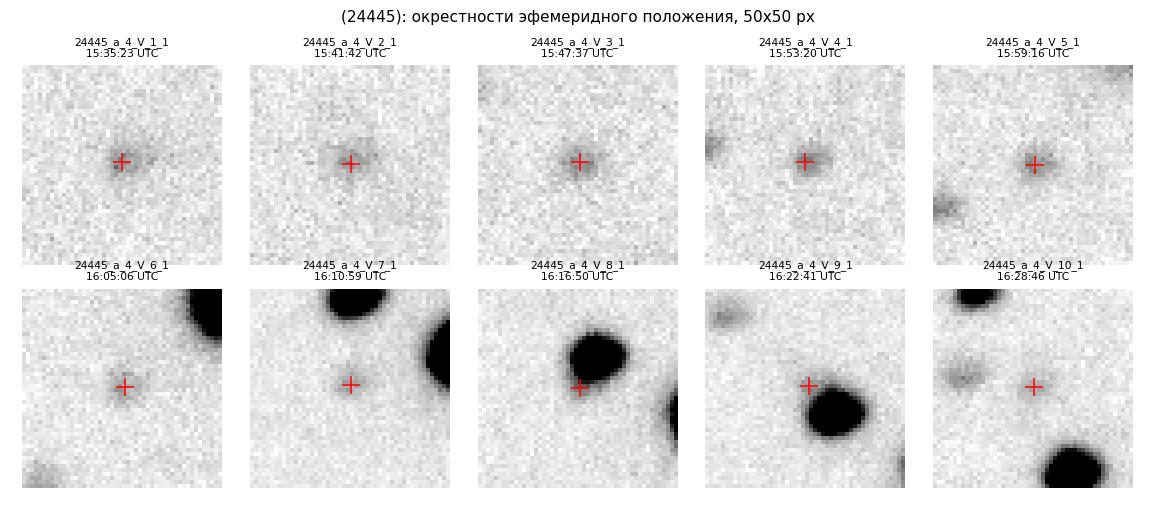

In [10]:
plot_asteroid_gallery(series)

## 8. Подробный разбор одного кадра

Кадр `vis_filename` (по умолчанию - средний кадр серии) обрабатывается с `verbose=True`:
печатается диагностика каждого шага и строятся контрольные картинки, включая измерения
контрольных звезд.

24445_a_4_V_6_1_stack.fits: 24445, фильтр V, 2026-09-29T16:05:06.289 UTC (JD 2461313.170212), обсерватория 217
Horizons: RA = 296.516612, DEC = 11.877782, V = 16.5, скорость 73.0"/ч, предсказанное положение x = 922.3, y = 870.9
звезд Gaia в кадре (G < 19.0): 3472, из них изолированных с G в (10.0, 18.5): 592
PSF-звезда: #1369, G = 10.29, пик 14281 ADU, фон 83.6 +- 18.2, FWHM ~ 7.6 px, в 34 px от астероида
редукция: uwex = 0.046", uwey = 0.056", измерено звезд Ns = 20, в решении Nrs = 19, масштаб 0.4897"/px
опорные звезды - от 81 до 262 px от астероида
астероид: x = 922.26, y = 870.57 (+-0.189 px), RA = 296.5166592, DEC = 11.8778067, O-C = (+0.166", +0.090"), ошибки RA*cos(DEC) = 0.072", DEC = 0.061"
  отношение потоков к PSF-звезде 0.0038 +- 0.0001, СКО остатков фита 8.2 ADU (фон PSF-звезды 18.2)
  бленд: звезда #1359, G = 18.67, в 19.5 px, сдвиг от предсказания 0.00 px (положение фиксировано), отношение потоков 0.0049
  бленд: звезда #1363, G = 18.81, в 15.2 px, сдвиг от предсказания 

,STAR,G,DIST,X,Y,OMC_RA,OMC_DEC,ERR_RA,ERR_DEC,ERR_PIX,FLUX_RATIO,N_BLEND
0,1372,18.09,22.5,933.62,852.25,0.772,-0.063,0.422,0.354,1.124,0.0006,0
1,1381,16.22,32.9,901.14,845.88,0.047,-0.056,0.067,0.058,0.175,0.0041,0
2,1364,12.83,35.5,920.24,906.14,0.031,-0.029,0.012,0.014,0.016,0.0754,2
3,1374,18.08,43.3,925.73,828.26,0.855,-0.278,0.304,0.256,0.811,0.0008,0


средние O-C контрольных звезд: RA*cos(DEC) = +0.426" +- 0.224", DEC = -0.106" +- 0.058"
СКО O-C одной звезды (0.577", 0.146") против средней формальной ошибки (0.201", 0.171")


,24445_a_4_V_6_1_stack.fits
FILE,24445_a_4_V_6_1_stack.fits
TARGET,24445
FILTER,V
DATE_OBS,2026-09-29T16:05:06.289
JD,2461313.170212
RA,296.516659
DEC,11.877807
ERR_RA,0.071577
ERR_DEC,0.061455
RA_EPH,296.516612


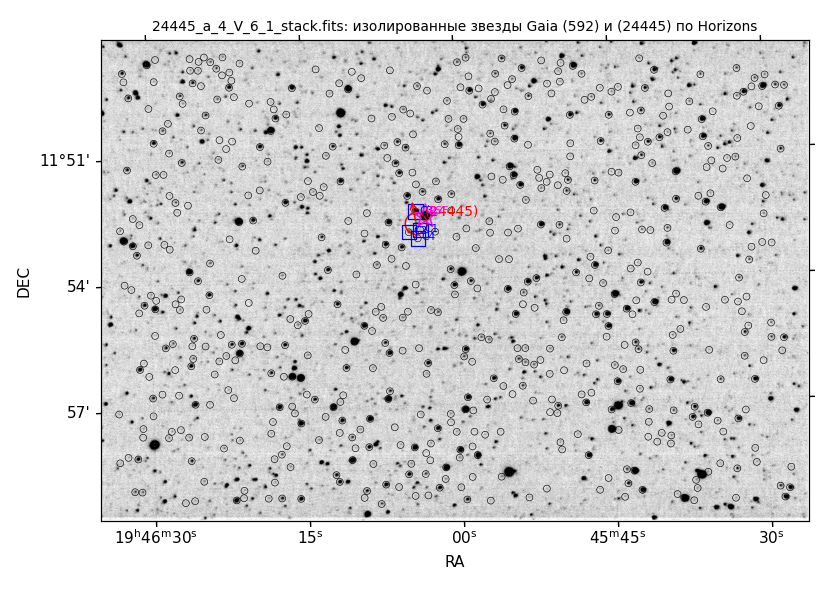

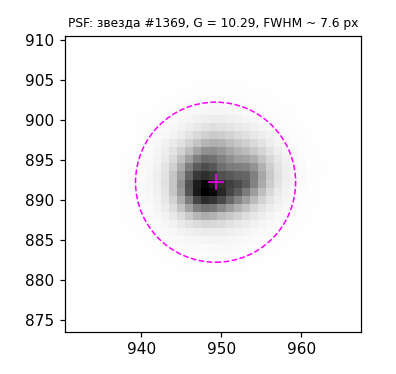

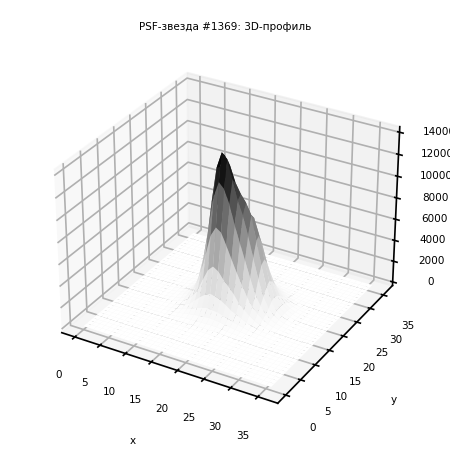

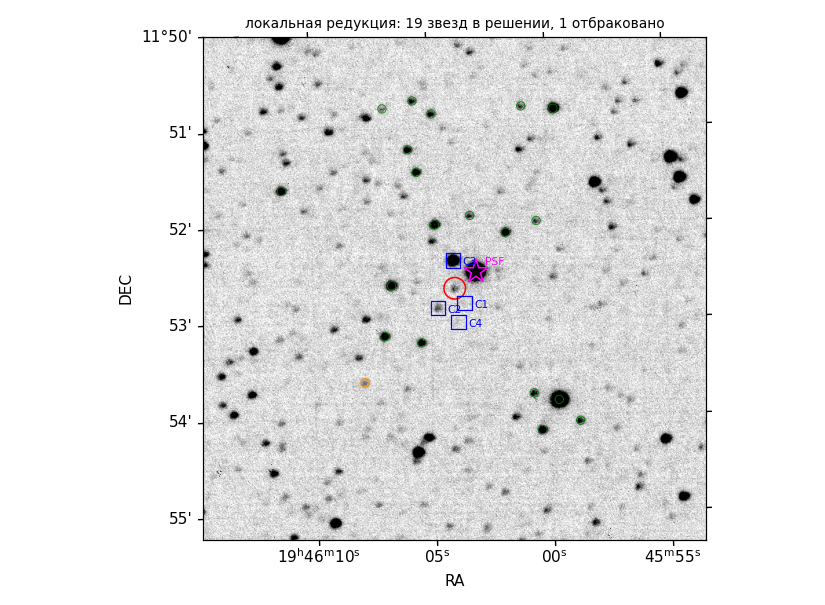

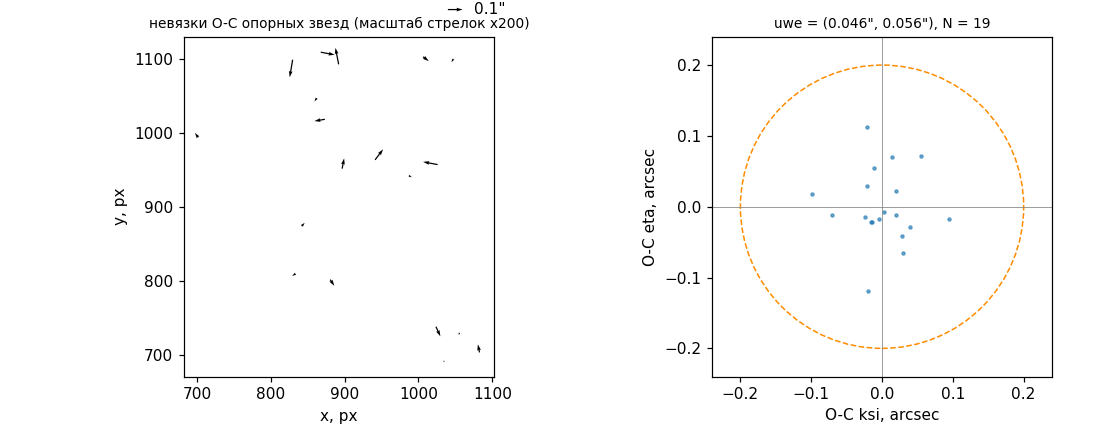

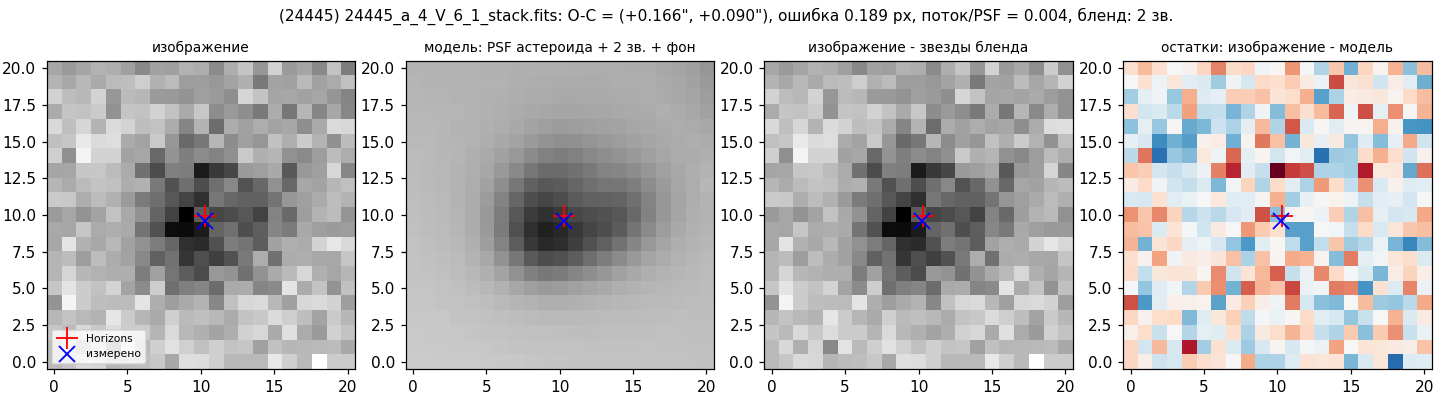

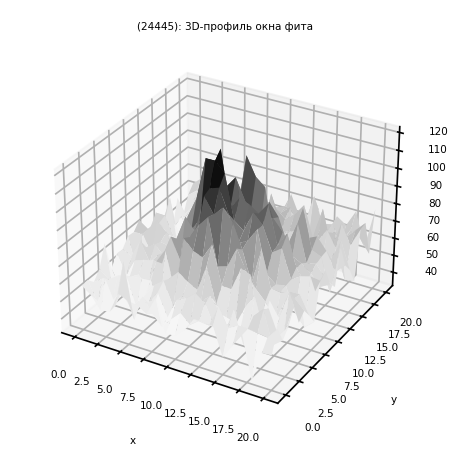

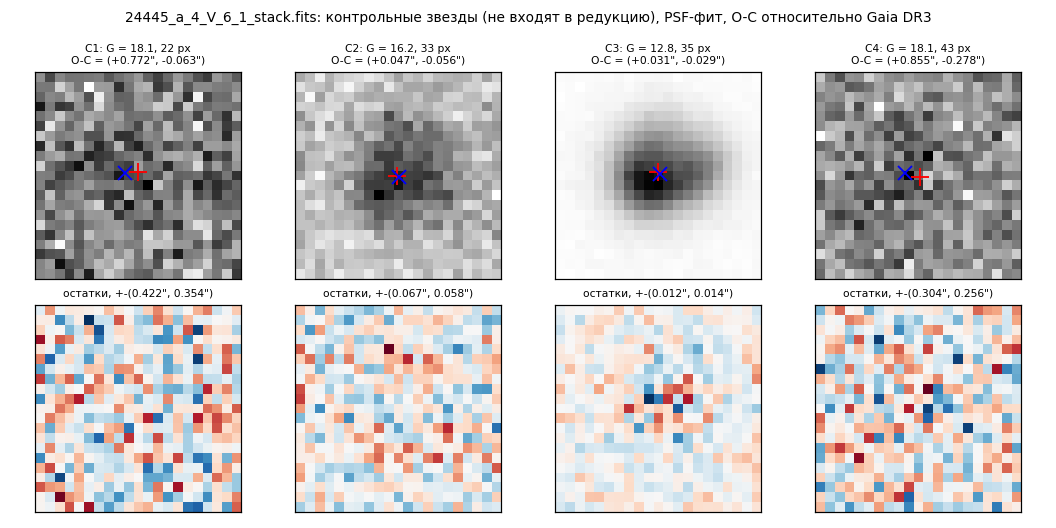

In [11]:
res_vis, ctrl_vis = process_frame(vis_filename, verbose=True)
pd.DataFrame([res_vis]).T.rename(columns={0: os.path.basename(vis_filename)})

## 9. Пакетная обработка серии

Все кадры серии обрабатываются без картинок. Кадр, на котором обработка упала, пропускается с
сообщением. Результаты сохраняются в `<TARGET>_<дата>_astrometry.csv`, измерения всех контрольных
звезд (`ctrl_all`, по строке на звезду и кадр) - в `<TARGET>_<дата>_control.csv` в текущей папке.

Колонки: `RA`, `DEC` - измеренные координаты (градусы, ICRF/Gaia DR3), `RA_EPH`, `DEC_EPH` - Horizons,
`ERR_RA` (по Δα·cosδ), `ERR_DEC` - ошибки положения в угловых секундах (ошибка центроида + ошибка
астрометрической модели в точке астероида, см. `position_errors`), `OMC_RA` (= Δα·cosδ), `OMC_DEC` - O-C
в угловых секундах, `ERR_PIX` - формальная ошибка положения в пикселях, `UWE_X`, `UWE_Y` - ошибка единицы веса астрометрической редукции, `NS`/`NRS` - число
измеренных опорных звезд и вошедших в решение, `SHIFT_PIX` - расстояние измеренного положения от
эфемеридного, `N_BLEND`, `BLEND_G` - число звезд бленда и G самой яркой из них, `FLUX_RATIO` - поток
астероида в единицах потока PSF-звезды, `BLEND_G`, `BLEND_DIST` - G звезды бленда и ее расстояние
от астероида (px), `MAG_PSF` - грубая оценка блеска по нему, `PSF_STAR`, `PSF_G`,
`FWHM` - PSF-звезда кадра, `FIT_RMS` - СКО остатков PSF-фита, `FLAG` - флаги качества (см. раздел 5),
`CTRL_*` - сводка по контрольным звездам кадра (см. `control_summary`).

In [12]:
def batch_process(filelist, omc_thresh=omc_thresh):
    """Прогоняет process_frame по всем файлам серии и собирает итоговую таблицу и таблицу измерений
    контрольных звезд. Кадр, упавший с исключением, пропускается с сообщением."""
    rows, ctrls = [], []
    for f in filelist:
        t_start = time.time()
        try:
            r, c = process_frame(f, verbose=False, omc_thresh=omc_thresh)
        except Exception as e:
            print(f'{os.path.basename(f)}: пропущен из-за ошибки: {e}')
            continue
        rows.append(r); ctrls.append(c)
        print(f"{r['FILE']}: O-C = ({r['OMC_RA']:+.3f}\", {r['OMC_DEC']:+.3f}\") "
              f"+-({r['ERR_RA']:.3f}\", {r['ERR_DEC']:.3f}\"), Nrs = {r['NRS']} {r['FLAG']:3s}| "
              f"контроль ({r['CTRL_N']}): ({r.get('CTRL_OMC_RA', nan):+.3f}\", {r.get('CTRL_OMC_DEC', nan):+.3f}\") "
              f"+-({r.get('CTRL_ERR_RA', nan):.3f}\", {r.get('CTRL_ERR_DEC', nan):.3f}\")  [{time.time()-t_start:.1f} с]")
    return pd.DataFrame(rows), (pd.concat(ctrls, ignore_index=True) if ctrls else pd.DataFrame())

resdf, ctrl_all = batch_process(filelist)
if len(resdf):
    out_csv = f"{resdf['TARGET'].iloc[0]}_{resdf['DATE_OBS'].iloc[0][:10].replace('-','')}_astrometry.csv"
    resdf.to_csv(out_csv, index=False, float_format='%.8f')
    ctrl_all.to_csv(out_csv.replace('_astrometry', '_control'), index=False, float_format='%.8f')
    print(f"сохранено: {out_csv}, {out_csv.replace('_astrometry', '_control')}")
else:
    print('ни один файл не дал измерений')
resdf.round({'RA':7,'DEC':7,'RA_EPH':7,'DEC_EPH':7,'OMC_RA':3,'OMC_DEC':3,'X':2,'Y':2,
             'ERR_RA':3,'ERR_DEC':3,'ERR_PIX':3,'SHIFT_PIX':2,'BLEND_G':2,'BLEND_DIST':1,'FLUX_RATIO':4,'FLUX_RATIO_ERR':4,
             'MAG_PSF':2,'PSF_G':2,'FWHM':2,'FIT_RMS':1,'UWE_X':3,'UWE_Y':3,
             'CTRL_OMC_RA':3,'CTRL_ERR_RA':3,'CTRL_OMC_DEC':3,'CTRL_ERR_DEC':3,'CTRL_RMS_RA':3,
             'CTRL_RMS_DEC':3,'CTRL_FERR_RA':3,'CTRL_FERR_DEC':3})

24445_a_4_V_1_1_stack.fits: O-C = (+0.100", +0.076") +-(0.054", 0.047"), Nrs = 18    | контроль (4): (-0.005", +0.157") +-(0.171", 0.112")  [1.5 с]
24445_a_4_V_2_1_stack.fits: O-C = (-0.011", -0.139") +-(0.070", 0.064"), Nrs = 17    | контроль (4): (+0.065", +0.272") +-(0.111", 0.120")  [1.5 с]
24445_a_4_V_3_1_stack.fits: O-C = (+0.222", +0.155") +-(0.284", 0.103"), Nrs = 13 e  | контроль (4): (+0.577", -0.130") +-(0.364", 0.308")  [1.5 с]
24445_a_4_V_4_1_stack.fits: O-C = (-0.097", -0.028") +-(0.063", 0.051"), Nrs = 19    | контроль (4): (+0.100", +0.024") +-(0.094", 0.009")  [1.5 с]
24445_a_4_V_5_1_stack.fits: O-C = (-0.079", -0.003") +-(0.062", 0.050"), Nrs = 20    | контроль (4): (-0.032", -0.129") +-(0.129", 0.101")  [1.5 с]
24445_a_4_V_6_1_stack.fits: O-C = (+0.166", +0.090") +-(0.072", 0.061"), Nrs = 19    | контроль (4): (+0.426", -0.106") +-(0.224", 0.058")  [0.6 с]
24445_a_4_V_7_1_stack.fits: O-C = (+0.134", +0.109") +-(0.066", 0.051"), Nrs = 19    | контроль (4): (-0.089", -

,FILE,TARGET,FILTER,DATE_OBS,JD,RA,DEC,ERR_RA,ERR_DEC,RA_EPH,...,FLAG,CTRL_N,CTRL_OMC_RA,CTRL_ERR_RA,CTRL_OMC_DEC,CTRL_ERR_DEC,CTRL_RMS_RA,CTRL_RMS_DEC,CTRL_FERR_RA,CTRL_FERR_DEC
0,24445_a_4_V_1_1_stack.fits,24445,V,2026-09-29T15:35:23.153,2.461313e+06,296.515053,11.887726,0.054,0.047,296.515025,...,,4,-0.005,0.171,0.157,0.112,0.296,0.250,0.162,0.158
1,24445_a_4_V_2_1_stack.fits,24445,V,2026-09-29T15:41:42.531,2.461313e+06,296.515357,11.885555,0.070,0.064,296.515360,...,,4,0.065,0.111,0.272,0.120,0.203,0.342,0.254,0.227
2,24445_a_4_V_3_1_stack.fits,24445,V,2026-09-29T15:47:37.758,2.461313e+06,296.515739,11.883660,0.284,0.103,296.515676,...,e,4,0.577,0.364,-0.130,0.308,0.854,0.549,0.192,0.162
3,24445_a_4_V_4_1_stack.fits,24445,V,2026-09-29T15:53:20.823,2.461313e+06,296.515954,11.881701,0.063,0.051,296.515981,...,,4,0.100,0.094,0.024,0.009,0.191,0.028,0.068,0.053
4,24445_a_4_V_5_1_stack.fits,24445,V,2026-09-29T15:59:16.009,2.461313e+06,296.516276,11.879731,0.062,0.050,296.516298,...,,4,-0.032,0.129,-0.129,0.101,0.226,0.218,0.169,0.138
5,24445_a_4_V_6_1_stack.fits,24445,V,2026-09-29T16:05:06.289,2.461313e+06,296.516659,11.877807,0.072,0.061,296.516612,...,,4,0.426,0.224,-0.106,0.058,0.577,0.146,0.201,0.171
6,24445_a_4_V_7_1_stack.fits,24445,V,2026-09-29T16:10:59.474,2.461313e+06,296.516968,11.875846,0.066,0.051,296.516930,...,,4,-0.089,0.209,-0.002,0.078,0.372,0.135,0.154,0.120
7,24445_a_4_V_8_1_stack.fits,24445,V,2026-09-29T16:16:50.253,2.461313e+06,296.517262,11.873890,0.083,0.078,296.517246,...,B,4,0.074,0.120,0.079,0.043,0.220,0.109,0.102,0.090
8,24445_a_4_V_9_1_stack.fits,24445,V,2026-09-29T16:22:41.904,2.461313e+06,296.517557,11.871835,0.108,0.082,296.517564,...,B,4,-0.176,0.214,0.108,0.025,0.411,0.116,0.175,0.131
9,24445_a_4_V_10_1_stack.fits,24445,V,2026-09-29T16:28:46.354,2.461313e+06,296.517928,11.869892,0.083,0.070,296.517895,...,,4,0.276,0.250,0.193,0.076,0.514,0.233,0.148,0.121


## 10. Итоги по серии

Трек астероида на кадре `vis_filename` (Horizons и измеренные положения) и O-C относительно Horizons
от времени. Для нумерованного астероида с хорошей орбитой средний O-C должен быть близок к нулю
в пределах точности редукции; систематический сдвиг по RA часто указывает на ошибку в моменте
наблюдения (1 с ошибки времени = скорость(″/ч)/3600 ″ сдвига вдоль направления движения) -
`estimate_time_offset` оценивает этот сдвиг по серии.

**Контроль по звездам за серию:** средние O-C всех измерений контрольных звезд (относительно Gaia) с
ошибками среднего - систематика редукции у астероида, которую не может объяснить ни эфемерида, ни
время. Отношение СКО O-C контрольных звезд к их средней формальной ошибке показывает, во сколько раз
занижены (>1) или завышены (<1) формальные ошибки `ERR_RA`, `ERR_DEC`.

отбракованы: 24445_a_4_V_3_1_stack.fits [e]
O-C по 9 из 10 измерений: RA*cos(DEC) = +0.040" +- 0.096", DEC = +0.002" +- 0.124"
вдоль трека O-C соответствует сдвигу времени dt = +0.2 +- 1.9 с (DATE_OBS_MODE = 'start'); поперек трека: -0.040" +- 0.036"

контрольные звезды: 40 измерений в 10 кадрах
  RA*cos(DEC) : средний O-C = +0.122" +- 0.067", СКО = 0.424", средняя формальная ошибка = 0.162" (СКО/ошибка = 2.6)
  DEC         : средний O-C = +0.047" +- 0.040", СКО = 0.253", средняя формальная ошибка = 0.137" (СКО/ошибка = 1.9)


/var/folders/hy/8vvv51316x9388z2zyw61jgm0000gn/T/ipykernel_68533/512161415.py:225: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(1, 3, figsize=(12,3.8), dpi=110, gridspec_kw={'width_ratios':[1.4,1.4,1]})


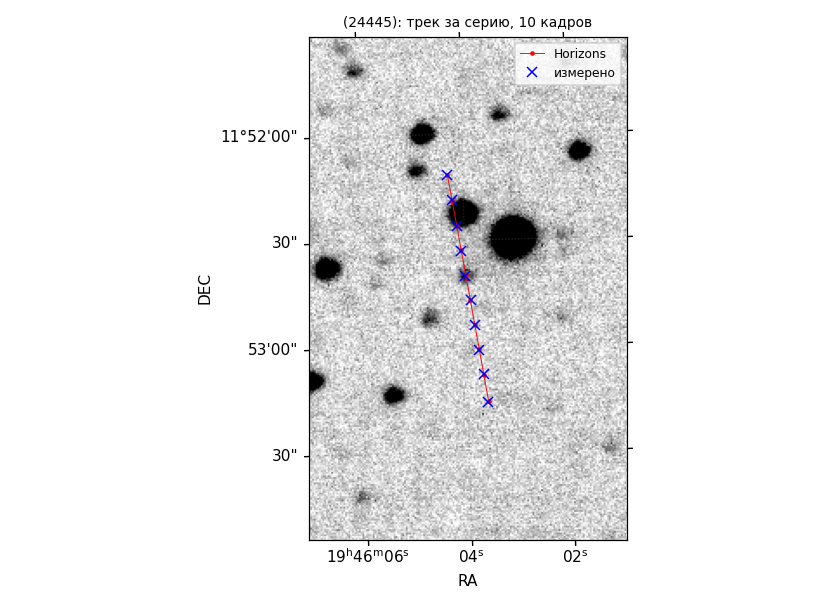

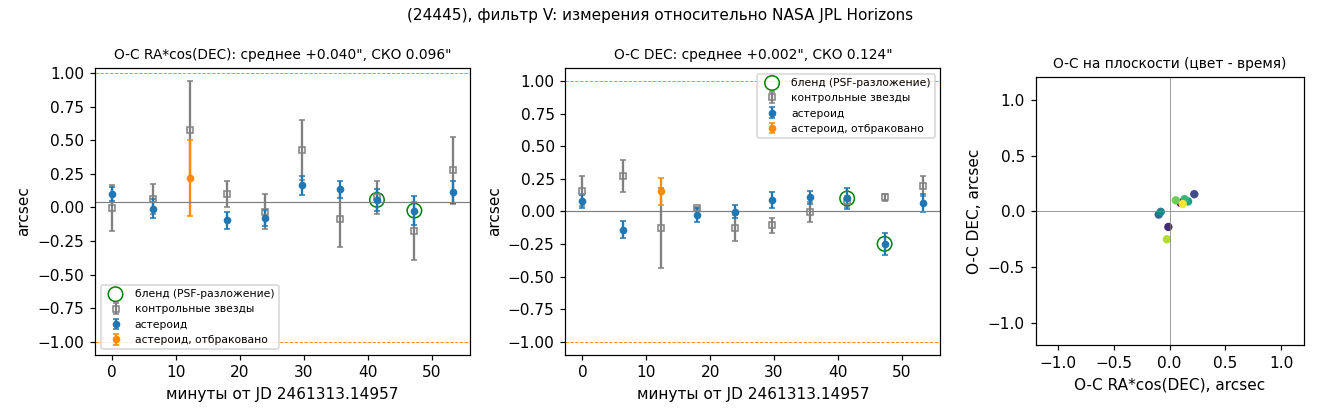

In [16]:
if len(resdf):
    plot_series_track(read_frame(vis_filename), series, resdf)
    plot_series_results(resdf)
    ok = good_rows(resdf)
    print('отбракованы:', ', '.join(f"{f} [{g}]" for f, g in zip(resdf['FILE'][~ok], resdf['FLAG'][~ok])) or 'нет')
    print(f"O-C по {ok.sum()} из {len(resdf)} измерений: "
          f"RA*cos(DEC) = {resdf['OMC_RA'][ok].mean():+.3f}\" +- {resdf['OMC_RA'][ok].std():.3f}\", "
          f"DEC = {resdf['OMC_DEC'][ok].mean():+.3f}\" +- {resdf['OMC_DEC'][ok].std():.3f}\"")
    to = estimate_time_offset(resdf)
    print(f"вдоль трека O-C соответствует сдвигу времени dt = {to['dt']:+.1f} +- {to['dt_err']:.1f} с "
          f"(DATE_OBS_MODE = '{DATE_OBS_MODE}'); поперек трека: {to['cross']:+.3f}\" +- {to['cross_err']:.3f}\"")
    if abs(to['dt']) > 3*to['dt_err'] and abs(to['dt']) > 5:
        print('  -> значимая ошибка момента наблюдения: проверьте DATE_OBS_MODE и часы регистрации времени')

if len(ctrl_all):
    n = len(ctrl_all)
    print(f"\nконтрольные звезды: {n} измерений в {ctrl_all['FILE'].nunique()} кадрах")
    for col, ecol, name in (('OMC_RA','ERR_RA','RA*cos(DEC)'), ('OMC_DEC','ERR_DEC','DEC')):
        o = ctrl_all[col]
        print(f"  {name:12s}: средний O-C = {o.mean():+.3f}\" +- {o.std()/sqrt(n):.3f}\", "
              f"СКО = {o.std():.3f}\", средняя формальная ошибка = {ctrl_all[ecol].mean():.3f}\" "
              f"(СКО/ошибка = {o.std()/ctrl_all[ecol].mean():.1f})")

## 10a. Разбор кадра с блендом

Если в серии есть кадры, где астероид "взаимодействует" со звездой (флаг `B`), здесь подробно
разбирается кадр с самым тесным блендом (наименьшее расстояние до звезды): на картинке окна фита видно, как блендированное
изображение раскладывается на PSF астероида и PSF звезды (панель "изображение - звезды бленда").

24445_a_4_V_8_1_stack.fits: 24445, фильтр V, 2026-09-29T16:16:50.253 UTC (JD 2461313.178359), обсерватория 217
Horizons: RA = 296.517246, DEC = 11.873862, V = 16.5, скорость 73.1"/ч, предсказанное положение x = 917.0, y = 899.7
звезд Gaia в кадре (G < 19.0): 3472, из них изолированных с G в (10.0, 18.5): 592
PSF-звезда: #1369, G = 10.29, пик 15954 ADU, фон 83.0 +- 16.4, FWHM ~ 7.3 px, в 34 px от астероида
редукция: uwex = 0.059", uwey = 0.048", измерено звезд Ns = 20, в решении Nrs = 20, масштаб 0.4898"/px
опорные звезды - от 80 до 280 px от астероида
астероид: x = 917.77, y = 899.86 (+-0.230 px), RA = 296.5172618, DEC = 11.8738898, O-C = (+0.056", +0.100"), ошибки RA*cos(DEC) = 0.083", DEC = 0.078"
  отношение потоков к PSF-звезде 0.0044 +- 0.0002, СКО остатков фита 12.8 ADU (фон PSF-звезды 16.4)
  бленд: звезда #1364, G = 12.83, в 7.4 px, сдвиг от предсказания 0.05 px, отношение потоков 0.0760
контрольные звезды (4), O-C относительно Gaia DR3, arcsec:


,STAR,G,DIST,X,Y,OMC_RA,OMC_DEC,ERR_RA,ERR_DEC,ERR_PIX,FLUX_RATIO,N_BLEND
0,1372,18.09,50.6,934.87,852.43,0.427,0.155,0.275,0.233,0.736,0.0008,0
1,1381,16.22,56.1,901.85,846.39,-0.033,0.001,0.058,0.049,0.151,0.0040,0
2,1327,14.23,56.5,897.34,952.24,-0.098,0.151,0.027,0.039,0.090,0.0248,2
3,1335,15.97,68.9,941.84,964.41,-0.000,0.009,0.046,0.039,0.118,0.0051,1


средние O-C контрольных звезд: RA*cos(DEC) = +0.074" +- 0.120", DEC = +0.079" +- 0.043"
СКО O-C одной звезды (0.220", 0.109") против средней формальной ошибки (0.102", 0.090")


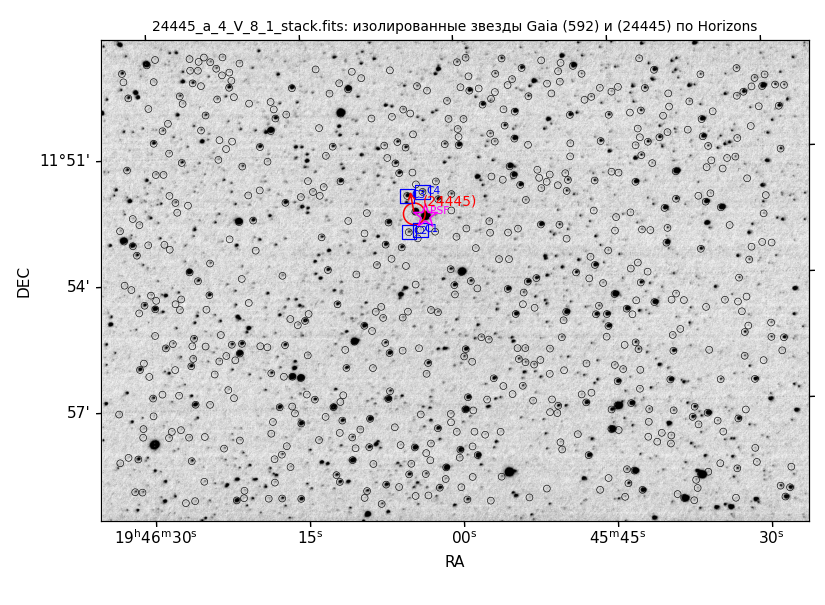

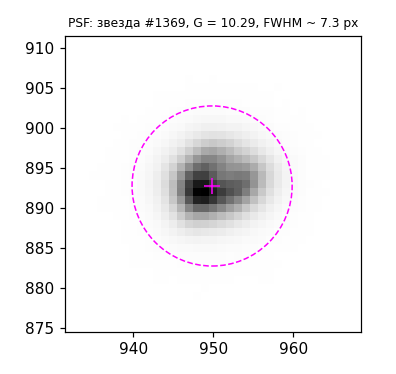

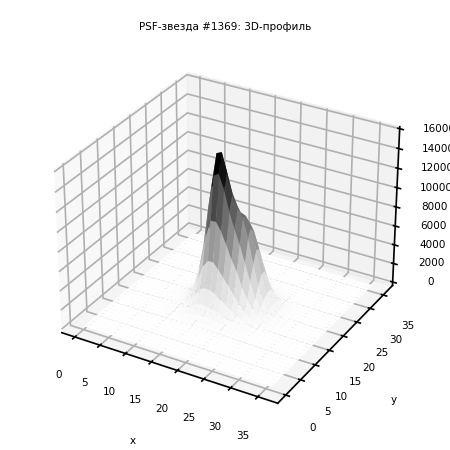

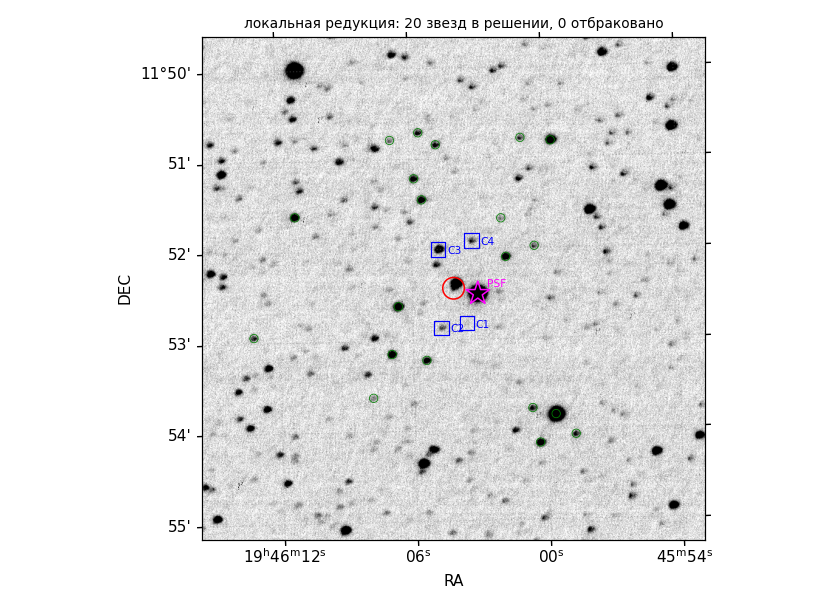

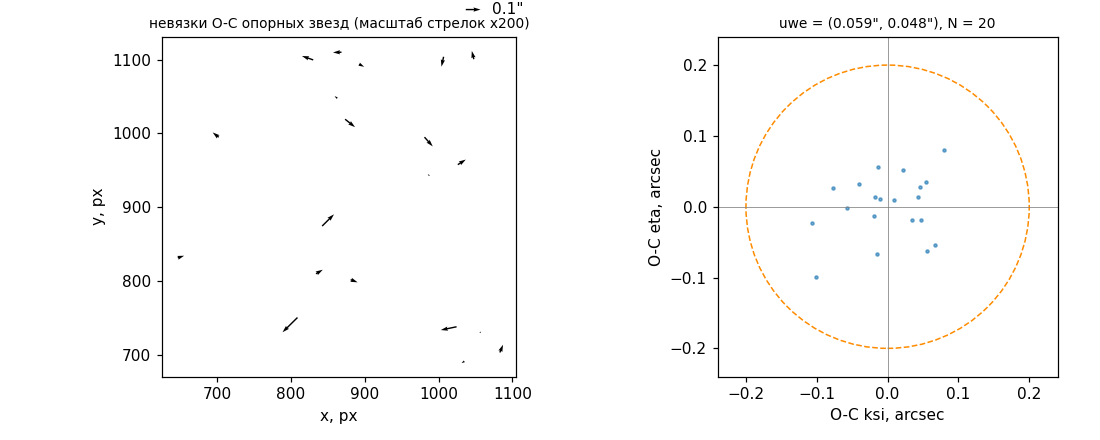

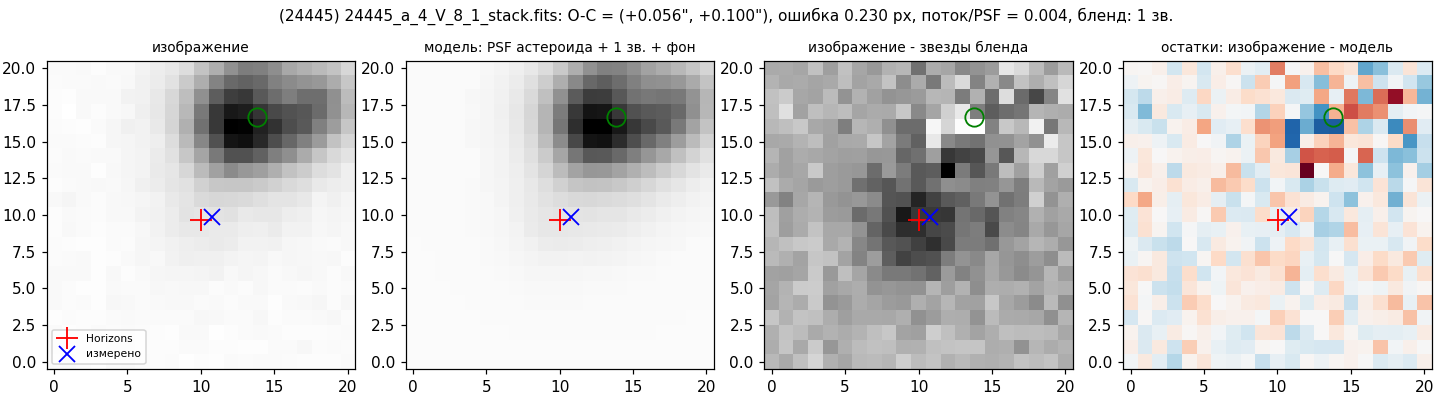

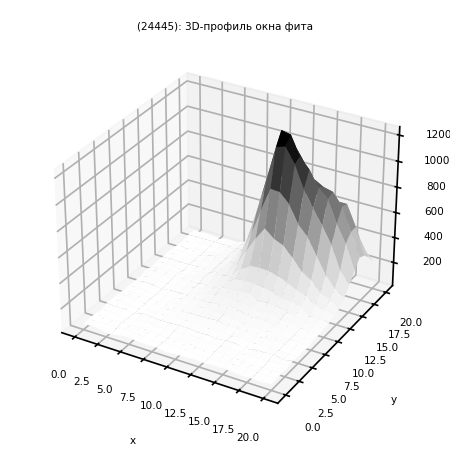

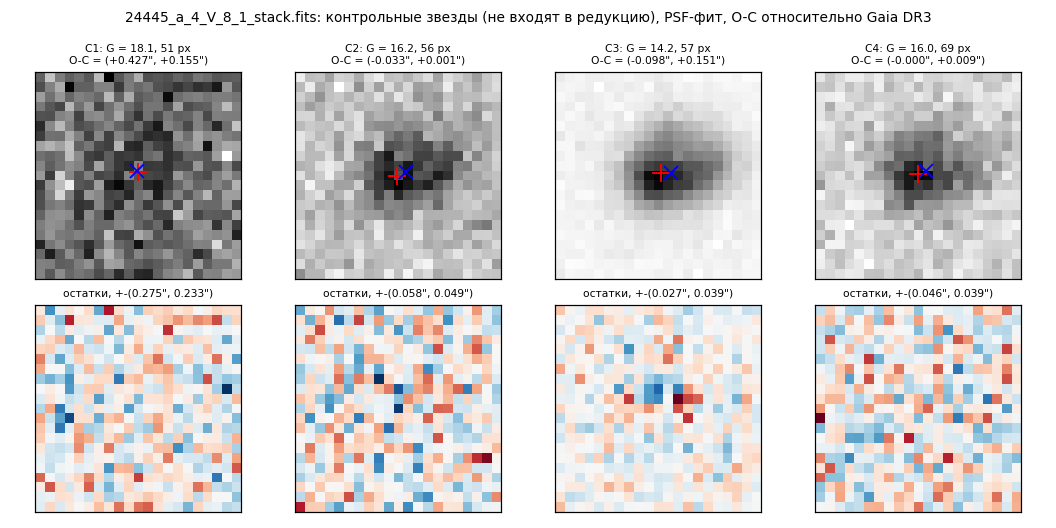

In [17]:
bl = resdf[resdf['FLAG'].str.contains('B')] if len(resdf) else resdf
if len(bl):
    blend_file = series.loc[series['FILE']==bl.sort_values('BLEND_DIST')['FILE'].iloc[0], 'PATH'].iloc[0]
    res_blend, ctrl_blend = process_frame(blend_file, verbose=True)
else:
    print('в серии нет кадров с блендом')

## 11. Итог: координаты астероида по серии

Итоговая таблица `result` (кадры без флагов отбраковки `s`, `e`, `?`; бленды `B` входят): момент наблюдения `JD` (UTC, середина экспозиции), измеренные `RA`, `DEC`
(градусы, ICRF, система Gaia DR3) и их ошибки `ERR_RA` (по Δα·cosδ), `ERR_DEC` в угловых секундах.
Сохраняется в `<TARGET>_<дата>_radec.csv`.

In [15]:
result = resdf.loc[good_rows(resdf), ['JD','RA','DEC','ERR_RA','ERR_DEC']].reset_index(drop=True)
if len(result):
    out_csv = f"{resdf['TARGET'].iloc[0]}_{resdf['DATE_OBS'].iloc[0][:10].replace('-','')}_radec.csv"
    result.to_csv(out_csv, index=False, float_format='%.9f')
    print(f'сохранено: {out_csv}')
result.style.format({'JD':'{:.6f}','RA':'{:.7f}','DEC':'{:.7f}','ERR_RA':'{:.3f}','ERR_DEC':'{:.3f}'})

сохранено: 24445_20260929_radec.csv


,JD,RA,DEC,ERR_RA,ERR_DEC
0,2461313.149574,296.5150532,11.8877255,0.054,0.047
1,2461313.153964,296.5153574,11.8855553,0.070,0.064
2,2461313.162047,296.5159537,11.8817007,0.063,0.051
3,2461313.166158,296.5162760,11.8797307,0.062,0.050
4,2461313.170212,296.5166592,11.8778067,0.072,0.061
5,2461313.174299,296.5169677,11.8758458,0.066,0.051
6,2461313.178359,296.5172618,11.8738898,0.083,0.078
7,2461313.182429,296.5175574,11.8718346,0.108,0.082
8,2461313.186648,296.5179285,11.8698922,0.083,0.070
